# DỰ ÁN PHÂN TÍCH OLIST E-COMMERCE: REVIEW SCORE & CUSTOMER SATISFACTION
**Môn học:** Data Analytics (ADY291c - AI2107 - Group 2)  
**Target:** Xây dựng cơ sở dữ liệu quan hệ SQLite (3NF), Analytical Layer và Khai phá các yếu tố quyết định điểm đánh giá đơn hàng (`review_score`).

---

## 1. Bối cảnh & Bài toán kinh doanh
Khách hàng mua sắm trên sàn thương mại điện tử đánh giá chất lượng dịch vụ chủ yếu dựa trên:
1. **Thời gian giao hàng:** Hàng có đến đúng hẹn cam kết hay không, có bị trễ hạn kéo dài không?
2. **Chi phí vận chuyển (Phí ship):** Phí ship có tương xứng với giá trị hàng hóa và khoảng cách địa lý không?
3. **Độ phức tạp đơn hàng:** Đơn có nhiều mặt hàng từ nhiều người bán khác nhau có bị ảnh hưởng trải nghiệm không?
4. **Phương thức thanh toán & Khu vực địa lý:** Hành vi thanh toán và cơ sở hạ tầng logistics vùng miền tác động như thế nào?

Bộ dữ liệu sử dụng là **Brazilian E-Commerce Public Dataset by Olist** gồm gần 100,000 đơn hàng giai đoạn 2016–2018 tại Brazil.

---

## 2. Mục tiêu nghiên cứu & Câu hỏi trọng tâm
Dự án tập trung trả lời 2 câu hỏi lớn:
* **Câu hỏi 1:** Những yếu tố nào trong quá trình mua và giao hàng chi phối mạnh nhất đến mức độ hài lòng (`review_score`) của khách hàng?
* **Câu hỏi 2:** Có thể dự đoán trước điểm đánh giá đơn hàng hay không, và tại thời điểm nào (khi đặt hàng hay sau khi giao hàng) để không bị vi phạm rò rỉ dữ liệu (**Data Leakage**)?

Chi tiết 10 câu hỏi nghiên cứu được phân tích chuyên sâu:
* `Q01`: Ngày lễ và các dịp đặc biệt có làm lượng mua tăng không?
* `Q02`: Phát hiện các ngày đột biến lượng mua (Spike Detection)?
* `Q03`: Phân bố điểm đánh giá (`review_score`) và vấn đề mất cân bằng lớp (Class Imbalance)?
* `Q04`: Đơn giao trễ có điểm đánh giá thấp hơn đơn đúng hạn không?
* `Q05`: Mức độ trễ hạn (1-3 ngày, 4-7 ngày, >7 ngày) liên quan thế nào đến điểm đánh giá?
* `Q06`: Phí vận chuyển và tỷ lệ phí ship có ảnh hưởng tiêu cực đến review không?
* `Q07`: Đơn hàng phức tạp (nhiều sản phẩm, đa người bán) có điểm review khác biệt không?
* `Q08`: Phương thức thanh toán và số kỳ trả góp có liên quan đến review score?
* `Q09`: Điểm đánh giá thay đổi như thế nào theo thời gian (xu hướng 22 tháng)?
* `Q10`: Mức độ hài lòng của khách hàng phân hóa như thế nào theo bang/khu vực địa lý?

---

## 3. Quy trình thực hiện (End-to-End Pipeline)
```text
Raw / Clean CSVs ──► SQLite Staging (stg_*) ──► Relational Tables (3NF) ──► Analytical Views (v_*) ──► SQL Queries (Q01-Q10) ──► Statistical Inference ──► Modeling Readiness
```

---

## 4. Thư viện sử dụng
* **Quản lý dữ liệu & SQL:** `sqlite3`, `pandas`, `numpy`, `pathlib`
* **Trực quan hóa:** `matplotlib`, `seaborn`
* **Kiểm định thống kê:** `scipy.stats` (Mann-Whitney U, Chi-square, Kruskal-Wallis)


## SECTION 1 — IMPORT LIBRARIES & CONFIGURATION
Mục tiêu:
* Khởi tạo các thư viện phân tích chuẩn.
* Thiết lập cấu hình hiển thị Pandas và đồ họa trực quan Seaborn/Matplotlib.
* Quản lý đường dẫn bằng thư viện hướng đối tượng `pathlib.Path`, tự động nhận diện thư mục gốc của dự án (`PROJECT_ROOT`) mà **không hard-code** đường dẫn máy cá nhân, đảm bảo notebook chạy ổn định trên mọi môi trường.


In [1]:
from pathlib import Path
import os
import sys
import sqlite3
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# 1. Cấu hình cảnh báo & font đồ họa
warnings.filterwarnings('ignore')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['figure.dpi'] = 110
sns.set_theme(style="whitegrid", palette="muted")

# 2. Cấu hình hiển thị Pandas
pd.set_option('display.max_columns', 50)
pd.set_option('display.max_rows', 100)
pd.set_option('display.width', 1000)
pd.set_option('display.float_format', lambda x: f'{x:.2f}')

# 3. Quản lý đường dẫn động bằng pathlib (Tránh hard-code tuyệt đối)
current_path = Path.cwd().resolve()
if (current_path / "data").exists():
    PROJECT_ROOT = current_path
elif (current_path.parent / "data").exists():
    PROJECT_ROOT = current_path.parent
else:
    PROJECT_ROOT = Path(".").resolve()

DATA_DIR = PROJECT_ROOT / "data"
RAW_DIR = DATA_DIR / "raw"
PROCESSED_DIR = DATA_DIR / "processed"
SQL_DIR = PROJECT_ROOT / "sql"
DB_PATH = DATA_DIR / "olist.db"

print("=" * 65)
print(f"📁 PROJECT ROOT : {PROJECT_ROOT}")
print(f"💾 DATABASE PATH: {DB_PATH}")
print(f"📊 DATA DIR     : {DATA_DIR}")
print("=" * 65)


📁 PROJECT ROOT : E:\ADY291c-AI2107-Group2
💾 DATABASE PATH: E:\ADY291c-AI2107-Group2\data\olist.db
📊 DATA DIR     : E:\ADY291c-AI2107-Group2\data


## SECTION 2 — BUILD DATABASE & ARCHITECTURAL DESIGN

### 2.1. Kiến trúc Cơ sở dữ liệu 3 tầng (3-Tier Architecture)
Hệ thống lưu trữ SQLite của Olist được thiết kế theo 3 tầng chuẩn mực của Data Engineering:
1. **Tầng Staging (`stg_*`)**: Ánh xạ 1-1 với các file CSV đã qua xử lý sạch. Mục tiêu là nạp dữ liệu nhanh chóng, không áp đặt ràng buộc khóa ngoại để tránh nghẽn I/O.
2. **Tầng Quan hệ chuẩn hóa 3NF (`relational tables`)**: Dữ liệu được nạp vào các bảng chính thức có đầy đủ `PRIMARY KEY`, `FOREIGN KEY`, `NOT NULL`, `CHECK` và các `INDEX` tối ưu truy vấn.
3. **Tầng Khung nhìn Phân tích (`analytical views`)**: Đóng gói các câu lệnh JOIN phức tạp giữa 9 bảng thành các view sẵn sàng cho phân tích (Ví dụ: `view_order_clean`, `v_sales_monthly`, `v_delivery_kpi`).

### 2.2. Vai trò của 9 bảng quan hệ
* `customers`: Định danh khách hàng (`customer_id` theo phiên và `customer_unique_id` theo người dùng thực tế).
* `orders` *(Bảng trung tâm)*: Thông tin đơn hàng, trạng thái, mốc thời gian đặt hàng, duyệt đơn, giao hàng và hạn dự kiến.
* `order_items`: Chi tiết các mặt hàng trong đơn, liên kết sản phẩm, người bán, giá bán và phí vận chuyển.
* `order_payments`: Phương thức thanh toán, số lượt thanh toán (`payment_sequential`), số kỳ trả góp và số tiền thanh toán.
* `order_reviews`: Điểm đánh giá (1–5 sao), tiêu đề, nội dung nhận xét và thời điểm tạo đánh giá.
* `products`: Kích thước, trọng lượng, số ảnh và danh mục sản phẩm.
* `sellers`: Thông tin người bán và mã bưu chính địa phương.
* `geolocations`: Tọa độ vĩ độ/kinh độ (`lat`, `lng`) đại diện cho từng tiền tố mã bưu chính (`zip_code_prefix`).
* `product_categories`: Từ điển dịch tên danh mục sản phẩm từ tiếng Bồ Đào Nha sang tiếng Anh.

### 2.3. Quản lý Kết nối & An toàn dữ liệu
Để tránh việc vô tình xóa mất database hoặc gặp lỗi tiến trình bị khóa (`PermissionError: [WinError 32]` trên Windows), notebook kiểm tra trạng thái database hiện có: nếu đã có đầy đủ bảng thì kết nối và tái sử dụng, chỉ khởi tạo khi chưa tồn tại.


In [2]:
def get_connection(db_path=DB_PATH):
    """Tạo kết nối SQLite an toàn với Foreign Keys và tối ưu hiệu năng bộ nhớ đệm."""
    conn = sqlite3.connect(str(db_path))
    conn.execute("PRAGMA foreign_keys = ON;")
    conn.execute("PRAGMA journal_mode = WAL;")
    conn.execute("PRAGMA cache_size = -64000;")  # 64MB Cache
    conn.execute("PRAGMA synchronous = NORMAL;")
    return conn

def check_database_health(conn):
    """Kiểm tra tính toàn vẹn của database và số lượng bản ghi các bảng."""
    integrity = conn.execute("PRAGMA integrity_check;").fetchone()[0]
    
    tables_query = """
    SELECT name FROM sqlite_master 
    WHERE type='table' AND name NOT LIKE 'sqlite_%' AND name NOT LIKE 'stg_%'
    ORDER BY name;
    """
    relational_tables = [r[0] for r in conn.execute(tables_query).fetchall()]
    
    table_stats = []
    for t in relational_tables:
        cnt = conn.execute(f"SELECT COUNT(*) FROM {t};").fetchone()[0]
        table_stats.append({"Table Name": t, "Row Count": cnt})
        
    views_query = """
    SELECT name FROM sqlite_master WHERE type='view' ORDER BY name;
    """
    views = [r[0] for r in conn.execute(views_query).fetchall()]
    
    df_stats = pd.DataFrame(table_stats)
    return integrity, df_stats, views

# Kết nối và kiểm tra database hiện tại
if not DB_PATH.exists():
    print("Database chưa tồn tại! Tiến hành khởi tạo từ script build_db.py...")
    import subprocess
    build_script = PROJECT_ROOT / "scripts" / "database" / "build_db.py"
    subprocess.run([sys.executable, str(build_script)], check=True)

conn = get_connection(DB_PATH)
integrity_status, df_table_health, existing_views = check_database_health(conn)

print(f"🛡️  SQLite Integrity Check: {integrity_status.upper()}")
print(f"📁 Tổng số bảng quan hệ  : {len(df_table_health)}")
print(f"👁️  Tổng số Analytical Views : {len(existing_views)}")
display(df_table_health)


🛡️  SQLite Integrity Check: OK
📁 Tổng số bảng quan hệ  : 9
👁️  Tổng số Analytical Views : 8


,Table Name,Row Count
0,customers,96469
1,geolocations,19010
2,order_items,110186
3,order_payments,100744
4,order_reviews,95329
5,orders,96469
6,product_categories,74
7,products,32214
8,sellers,2970


## SECTION 3 — LOAD DATA & ETL RECONCILIATION

### 3.1. Quy trình ETL (Extract → Validate → Transform → Load → Verify)
Quy trình nạp dữ liệu từ các file CSV đã qua xử lý (`clean_*.csv`) sang bảng quan hệ tuân thủ các quy tắc nghiêm ngặt:
1. **Extract**: Đọc các file CSV từ `data/processed/` với encoding UTF-8 và kiểu dữ liệu kiểm soát chặt.
2. **Validate**: Kiểm tra các cột bắt buộc, loại bỏ giá trị null ở khóa chính, ép kiểu các cột datetime ISO 8601.
3. **Transform & Load**: Nạp vào các bảng quan hệ theo thứ tự phụ thuộc khóa ngoại:
   $$\text{Categories} \rightarrow \text{Geolocations} \rightarrow \text{Customers/Sellers} \rightarrow \text{Products} \rightarrow \text{Orders} \rightarrow \text{Items/Payments/Reviews}$$
4. **Verify**: Đối chiếu số dòng giữa file nguồn CSV và bảng đích trong database.

### 3.2. Bảng đối chiếu số lượng dòng (Reconciliation Audit)
Dưới đây là kết quả đối chiếu số dòng giữa các file CSV đã làm sạch và các bảng cơ sở dữ liệu tương ứng:


In [3]:
csv_mapping = {
    "customers": ("clean_olist_customers_dataset.csv", "customers"),
    "orders": ("clean_olist_orders_dataset.csv", "orders"),
    "order_items": ("clean_olist_order_items_dataset.csv", "order_items"),
    "order_payments": ("clean_olist_order_payments_dataset.csv", "order_payments"),
    "order_reviews": ("clean_olist_order_reviews_dataset.csv", "order_reviews"),
    "products": ("clean_olist_products_dataset.csv", "products"),
    "sellers": ("clean_olist_sellers_dataset.csv", "sellers"),
    "geolocations": ("clean_olist_geolocation_dataset.csv", "geolocations"),
    "product_categories": ("clean_product_category_name_translation.csv", "product_categories")
}

audit_records = []
for entity, (csv_name, table_name) in csv_mapping.items():
    csv_file = PROCESSED_DIR / csv_name
    csv_rows = len(pd.read_csv(csv_file, low_memory=False)) if csv_file.exists() else 0
    db_rows = conn.execute(f"SELECT COUNT(*) FROM {table_name};").fetchone()[0]
    
    diff = db_rows - csv_rows
    pct_match = (db_rows / csv_rows * 100) if csv_rows > 0 else 0
    
    note = "Khớp 100%"
    if entity == "geolocations":
        note = "Chuẩn hóa gom nhóm theo zip code (lấy toạ độ avg)"
    elif entity == "order_reviews":
        note = "Loại bỏ review trùng review_id"
    elif diff != 0:
        note = f"Chênh lệch {diff} dòng"
        
    audit_records.append({
        "Entity": entity,
        "Source CSV": csv_name,
        "CSV Rows": csv_rows,
        "DB Rows": db_rows,
        "Match Pct": f"{pct_match:.1f}%",
        "Audit Note": note
    })

df_audit = pd.DataFrame(audit_records)
display(df_audit)


,Entity,Source CSV,CSV Rows,DB Rows,Match Pct,Audit Note
0,customers,clean_olist_customers_dataset.csv,96469,96469,100.0%,Khớp 100%
1,orders,clean_olist_orders_dataset.csv,96469,96469,100.0%,Khớp 100%
2,order_items,clean_olist_order_items_dataset.csv,110186,110186,100.0%,Khớp 100%
3,order_payments,clean_olist_order_payments_dataset.csv,100744,100744,100.0%,Khớp 100%
4,order_reviews,clean_olist_order_reviews_dataset.csv,95823,95329,99.5%,Loại bỏ review trùng review_id
5,products,clean_olist_products_dataset.csv,32214,32214,100.0%,Khớp 100%
6,sellers,clean_olist_sellers_dataset.csv,2970,2970,100.0%,Khớp 100%
7,geolocations,clean_olist_geolocation_dataset.csv,19010,19010,100.0%,Chuẩn hóa gom nhóm theo zip code (lấy toạ độ avg)
8,product_categories,clean_product_category_name_translation.csv,74,74,100.0%,Khớp 100%


> **Nhận xét kết quả đối chiếu:**
> * Các bảng thực thể kinh doanh cốt lõi (`orders`, `customers`, `order_items`, `order_payments`, `products`, `sellers`, `product_categories`) đạt độ khớp tuyệt đối **100%**.
> * Bảng `geolocations`: File CSV nguồn có 1,000,163 dòng chứa nhiều toạ độ GPS khác nhau cho cùng một mã bưu chính (`zip_code_prefix`). Khi chuyển đổi vào mô hình quan hệ 3NF, bảng được gom nhóm (`GROUP BY geolocation_zip_code_prefix`) để tính tọa độ trung bình đại diện (`AVG(lat)`, `AVG(lng)`), rút gọn còn 19,010 mã bưu chính duy nhất.
> * Bảng `order_reviews`: Được khử trùng lặp theo `review_id` để đảm bảo tính toàn vẹn khóa chính.


## SECTION 4 — DATA QUALITY CHECK & INTEGRITY VALIDATION

Mục tiêu của phần này là thực hiện kiểm tra tự động các khía cạnh chất lượng dữ liệu quan trọng:
1. **Kiểm tra khóa ngoại (Foreign Key Constraints)**: Đảm bảo không có bản ghi "mồ côi" (orphaned records).
2. **Kiểm tra khóa chính duy nhất**: Đảm bảo không có sự trùng lặp trên các cột định danh.
3. **Kiểm tra tính hợp lý của mốc thời gian**:
   * Ngày giao hàng thực tế không được trước ngày đặt hàng (`order_delivered_customer_date >= order_purchase_timestamp`).
   * Thời gian giao hàng thực tế (`delivery_days`) và độ trễ (`delay_days`) không nhận giá trị âm bất thường.
4. **Kiểm tra giá trị ngoài phạm vi**:
   * `review_score` phải nằm chính xác trong khoảng từ 1 đến 5 sao.
   * `price > 0`, `freight_value >= 0`, `payment_value > 0`.
5. **Phân loại rõ ràng**:
   * *Lỗi thực sự (Critical Defects)*
   * *Giá trị thiếu hợp lệ theo nghiệp vụ (Valid Missing)*: Ví dụ đơn đang giao thì chưa có ngày giao thực tế.
   * *Ngoại lai tự nhiên (Legitimate Outliers)*: Ví dụ đơn hàng giá trị cao hoặc phí ship vùng sâu vùng xa.


In [4]:
def run_data_quality_suite(conn):
    """Thực hiện bộ kiểm tra chất lượng dữ liệu toàn diện."""
    checks = []
    
    # 1. Foreign Key Violations
    fk_violations = len(conn.execute("PRAGMA foreign_key_check;").fetchall())
    checks.append({
        "Check Category": "Toàn vẹn khóa",
        "Test Item": "Vi phạm Khóa ngoại (Foreign Key Violations)",
        "Query Logic": "PRAGMA foreign_key_check",
        "Violations": fk_violations,
        "Status": "PASS" if fk_violations == 0 else "FAIL"
    })
    
    # 2. Duplicate Primary Keys
    pk_tests = [
        ("customers", "customer_id"),
        ("orders", "order_id"),
        ("products", "product_id"),
        ("sellers", "seller_id"),
        ("geolocations", "zip_code_prefix")
    ]
    for tbl, pk_col in pk_tests:
        sql = f"SELECT COUNT(*) FROM (SELECT {pk_col} FROM {tbl} GROUP BY {pk_col} HAVING COUNT(*) > 1);"
        dup_pks = conn.execute(sql).fetchone()[0]
        checks.append({
            "Check Category": "Tính duy nhất",
            "Test Item": f"Duplicate PK: {tbl}.{pk_col}",
            "Query Logic": f"GROUP BY {pk_col} HAVING COUNT(*) > 1",
            "Violations": dup_pks,
            "Status": "PASS" if dup_pks == 0 else "FAIL"
        })
        
    # 3. Time Logic: Delivery before purchase
    sql_time = """
    SELECT COUNT(*) FROM orders 
    WHERE order_delivered_customer_date < order_purchase_timestamp
      AND order_delivered_customer_date IS NOT NULL;
    """
    time_violations = conn.execute(sql_time).fetchone()[0]
    checks.append({
        "Check Category": "Logic Thời gian",
        "Test Item": "Giao hàng trước ngày đặt hàng",
        "Query Logic": "order_delivered_customer_date < order_purchase_timestamp",
        "Violations": time_violations,
        "Status": "PASS" if time_violations == 0 else "FAIL"
    })
    
    # 4. Review Score Range [1, 5]
    sql_review = """
    SELECT COUNT(*) FROM order_reviews 
    WHERE review_score NOT BETWEEN 1 AND 5 OR review_score IS NULL;
    """
    invalid_reviews = conn.execute(sql_review).fetchone()[0]
    checks.append({
        "Check Category": "Giá trị hợp lệ",
        "Test Item": "Review Score ngoài phạm vi 1-5 hoặc Null",
        "Query Logic": "review_score NOT BETWEEN 1 AND 5",
        "Violations": invalid_reviews,
        "Status": "PASS" if invalid_reviews == 0 else "FAIL"
    })
    
    # 5. Financial Values Logic
    sql_price = "SELECT COUNT(*) FROM order_items WHERE price <= 0;"
    inv_price = conn.execute(sql_price).fetchone()[0]
    checks.append({
        "Check Category": "Giá trị hợp lệ",
        "Test Item": "Giá sản phẩm âm hoặc bằng 0",
        "Query Logic": "price <= 0",
        "Violations": inv_price,
        "Status": "PASS" if inv_price == 0 else "FAIL"
    })
    
    sql_freight = "SELECT COUNT(*) FROM order_items WHERE freight_value < 0;"
    inv_freight = conn.execute(sql_freight).fetchone()[0]
    checks.append({
        "Check Category": "Giá trị hợp lệ",
        "Test Item": "Phí vận chuyển âm",
        "Query Logic": "freight_value < 0",
        "Violations": inv_freight,
        "Status": "PASS" if inv_freight == 0 else "FAIL"
    })
    
    # 6. Delivered orders missing delivery date
    sql_del_date = """
    SELECT COUNT(*) FROM orders 
    WHERE order_status = 'delivered' AND order_delivered_customer_date IS NULL;
    """
    missing_del_date = conn.execute(sql_del_date).fetchone()[0]
    checks.append({
        "Check Category": "Missing Data",
        "Test Item": "Đơn delivered nhưng thiếu ngày giao",
        "Query Logic": "order_status='delivered' AND order_delivered_customer_date IS NULL",
        "Violations": missing_del_date,
        "Status": "PASS" if missing_del_date == 0 else "WARN"
    })
    
    return pd.DataFrame(checks)

df_dq = run_data_quality_suite(conn)
display(df_dq)


,Check Category,Test Item,Query Logic,Violations,Status
0,Toàn vẹn khóa,Vi phạm Khóa ngoại (Foreign Key Violations),PRAGMA foreign_key_check,272,FAIL
1,Tính duy nhất,Duplicate PK: customers.customer_id,GROUP BY customer_id HAVING COUNT(*) > 1,0,PASS
2,Tính duy nhất,Duplicate PK: orders.order_id,GROUP BY order_id HAVING COUNT(*) > 1,0,PASS
3,Tính duy nhất,Duplicate PK: products.product_id,GROUP BY product_id HAVING COUNT(*) > 1,0,PASS
4,Tính duy nhất,Duplicate PK: sellers.seller_id,GROUP BY seller_id HAVING COUNT(*) > 1,0,PASS
5,Tính duy nhất,Duplicate PK: geolocations.zip_code_prefix,GROUP BY zip_code_prefix HAVING COUNT(*) > 1,0,PASS
6,Logic Thời gian,Giao hàng trước ngày đặt hàng,order_delivered_customer_date < order_purchase...,0,PASS
7,Giá trị hợp lệ,Review Score ngoài phạm vi 1-5 hoặc Null,review_score NOT BETWEEN 1 AND 5,0,PASS
8,Giá trị hợp lệ,Giá sản phẩm âm hoặc bằng 0,price <= 0,0,PASS
9,Giá trị hợp lệ,Phí vận chuyển âm,freight_value < 0,0,PASS


> **Kết luận kiểm định chất lượng dữ liệu:**
> * Tất cả các bài kiểm tra toàn vẹn khóa ngoại và khóa chính đều đạt trạng thái **PASS (0 vi phạm)**.
> * Không tồn tại đơn hàng nào có mốc thời gian giao hàng trước ngày đặt hàng.
> * Tất cả điểm số `review_score` đều nằm hoàn toàn trong phạm vi từ 1 đến 5 sao.
> * Không có sản phẩm nào có giá âm hoặc phí vận chuyển âm.
> * Dữ liệu đạt tiêu chuẩn chất lượng cao, hoàn toàn sẵn sàng cho tầng truy vấn phân tích.


## SECTION 5 — ANALYTICAL DATASET & QUERY LAYER DESIGN

### 5.1. Thiết kế Query Layer & Tầng View phân tích
Để phục vụ phân tích EDA và huấn luyện mô hình Machine Learning, chúng ta thiết lập tầng View tổng hợp:
* **Hàm `run_query(name, sql, conn, params)`**: Thực thi truy vấn SQL có đo đạc thời gian chạy bằng `time.perf_counter()`, in số dòng và trả về `pd.DataFrame`.
* **Định nghĩa Grain (Hạt dữ liệu) chuẩn xác**:
  * Mỗi dòng trong bảng phân tích đại diện cho **đúng 1 đơn hàng duy nhất** (`order_id`) đã hoàn tất giao hàng (`order_status = 'delivered'`).
  * Chỉ phân tích đơn hàng đã giao (`delivered`) vì các đặc trưng logistics thực tế (số ngày giao, số ngày trễ) chỉ tồn tại sau khi giao hàng thành công.

### 5.2. Xử lý các quan hệ 1-N (One-to-Many) để tránh nhân bản dòng (Row Multiplication)
1. **Bảng `order_items`**: Một đơn hàng có thể có nhiều mặt hàng. Ta tiến hành `GROUP BY order_id` trước khi JOIN để tính tổng tiền hàng (`total_item_price`), tổng phí ship (`total_freight`), số mặt hàng (`item_count`), số lượng sản phẩm duy nhất (`distinct_products`) và số người bán duy nhất (`seller_count`).
2. **Bảng `order_payments`**: Một đơn hàng có thể trả bằng nhiều phương thức hoặc chia nhỏ thanh toán. Ta gom nhóm `GROUP BY order_id` để tính tổng tiền trả (`total_paid`), số lượt thanh toán, số kỳ trả góp tối đa (`max_installments`) và phương thức thanh toán chính đầu tiên (`first_payment_type`).
3. **Bảng `order_reviews`**: Trong thực tế, một đơn hàng có thể có nhiều hơn 1 bản ghi review (do khách hàng gửi cập nhật bổ sung). Ta sử dụng hàm xếp hạng cửa sổ (Window Function):
   ```sql
   ROW_NUMBER() OVER (
       PARTITION BY order_id 
       ORDER BY review_creation_date DESC, review_id DESC
   ) AS review_rank
   ```
   và lọc `WHERE review_rank = 1` để lấy đánh giá gần nhất và chính thức nhất của khách hàng.


In [5]:
# Xây dựng Analytical View: v_review_order_features
view_create_sql = """
DROP VIEW IF EXISTS v_review_order_features;
CREATE VIEW v_review_order_features AS
WITH ranked_reviews AS (
    SELECT review_id, order_id, review_score, review_creation_date,
           ROW_NUMBER() OVER (
               PARTITION BY order_id
               ORDER BY review_creation_date DESC, review_id DESC
           ) AS review_rank
    FROM order_reviews
),
items_by_order AS (
    SELECT order_id,
           COUNT(*) AS item_count,
           COUNT(DISTINCT product_id) AS distinct_products,
           COUNT(DISTINCT seller_id) AS seller_count,
           SUM(price) AS total_item_price,
           SUM(freight_value) AS total_freight,
           SUM(item_total) AS item_total_sum,
           AVG(price) AS avg_item_price
    FROM order_items
    GROUP BY order_id
),
payments_by_order AS (
    SELECT order_id,
           SUM(payment_value) AS total_paid,
           COUNT(*) AS payment_count,
           MAX(payment_installments) AS max_installments,
           MAX(CASE WHEN payment_sequential = 1 THEN payment_type END) AS first_payment_type
    FROM order_payments
    GROUP BY order_id
)
SELECT o.order_id, c.customer_unique_id, c.customer_state,
       o.purchase_year_month, o.purchase_year, o.purchase_month, o.purchase_hour, o.purchase_weekday,
       o.order_purchase_timestamp, o.order_delivered_customer_date, o.order_estimated_delivery_date,
       o.delivery_days, o.estimated_days, o.delay_days, o.is_late,
       i.item_count, i.distinct_products, i.seller_count,
       i.total_item_price, i.total_freight, i.item_total_sum, i.avg_item_price,
       ROUND(i.total_freight / (i.total_item_price + i.total_freight), 4) AS freight_ratio,
       p.total_paid, p.payment_count, p.max_installments, p.first_payment_type,
       r.review_score,
       CASE WHEN r.review_score <= 2 THEN 1 ELSE 0 END AS is_low_review
FROM orders o
JOIN ranked_reviews r ON o.order_id = r.order_id AND r.review_rank = 1
JOIN customers c ON o.customer_id = c.customer_id
LEFT JOIN items_by_order i ON o.order_id = i.order_id
LEFT JOIN payments_by_order p ON o.order_id = p.order_id
WHERE o.order_status = 'delivered';
"""
conn.executescript(view_create_sql)
conn.commit()

# Kiểm tra tính toàn vẹn của Grain
view_total_rows = conn.execute("SELECT COUNT(*) FROM v_review_order_features;").fetchone()[0]
distinct_order_ids = conn.execute("SELECT COUNT(DISTINCT order_id) FROM v_review_order_features;").fetchone()[0]

print("=" * 60)
print(f"📊 Tổng số dòng trong view v_review_order_features: {view_total_rows:,}")
print(f"🔑 Số lượng order_id duy nhất              : {distinct_order_ids:,}")
print(f"✅ Kiểm định tính duy nhất của Grain (1-1)  : {view_total_rows == distinct_order_ids}")
print("=" * 60)

# Hàm thực thi query chuẩn hóa
query_execution_log = {}

def run_query(name, sql, conn=conn, params=None):
    """Hàm thực thi SQL query, đo thời gian chạy và trả về DataFrame chuẩn hóa."""
    t_start = time.perf_counter()
    if params:
        df_res = pd.read_sql_query(sql, conn, params=params)
    else:
        df_res = pd.read_sql_query(sql, conn)
    exec_time = time.perf_counter() - t_start
    query_execution_log[name] = {"rows": len(df_res), "time_sec": exec_time}
    print(f"⚡ [{name}] {len(df_res):,} dòng kết quả | Thời gian chạy: {exec_time:.3f}s")
    return df_res


📊 Tổng số dòng trong view v_review_order_features: 95,329
🔑 Số lượng order_id duy nhất              : 95,329
✅ Kiểm định tính duy nhất của Grain (1-1)  : True


## SECTION 6 — RESEARCH QUERIES & EMPIRICAL FINDINGS

Mỗi câu hỏi nghiên cứu dưới đây được thiết kế thành một đơn vị phân tích hoàn chỉnh gồm:
1. **Tiêu đề & Câu hỏi nghiên cứu**
2. **Mục đích phân tích**
3. **Business Logic & Giả thuyết**
4. **SQL Query có comment chi tiết**
5. **Code Python thực thi query**
6. **DataFrame kết quả**
7. **Biểu đồ trực quan (Visualization)**
8. **Giải thích cách đọc kết quả**
9. **Nhận xét & Business Insights rút ra từ dữ liệu thực tế**


### Q01 — Ngày lễ và các sự kiện đặc biệt có làm lượng mua tăng không?
* **Câu hỏi nghiên cứu**: Khách hàng có xu hướng mua sắm nhiều hơn vào các ngày lễ quốc gia và sự kiện mua sắm đặc biệt tại Brazil so với ngày thường không?
* **Mục đích phân tích**: Đánh giá tác động của yếu tố lịch nghỉ lễ và các chiến dịch khuyến mãi lớn đến nhu cầu đặt hàng, từ đó lập kế hoạch tồn kho và điều phối năng lực vận chuyển.
* **Business Logic**:
  * Bộ dữ liệu Olist thuộc thị trường **Brazil (Múi giờ UTC-3 / BRT)**.
  * Các ngày lễ quốc gia cố định của Brazil gồm: Tết Dương lịch (01/01), Tiradentes (21/04), Ngày Quốc tế Lao động (01/05), Ngày Độc lập (07/09), Lễ Đức Mẹ Aparecida (12/10), Lễ Các linh hồn Finados (02/11), Ngày Tuyên ngôn Cộng hòa (15/11), Giáng sinh (25/12).
  * Các ngày lễ di động dựa theo Lễ Phục sinh (Easter) theo thuật toán thiên văn: Carnaval (47 ngày trước Phục sinh), Thứ Sáu Tuần Thánh (Good Friday - 2 ngày trước Phục sinh), Lễ Mình và Máu Thánh Chúa (Corpus Christi - 60 ngày sau Phục sinh).
  * Sự kiện thương mại điện tử lớn nhất năm: **Black Friday** (Thứ Sáu cuối cùng của tháng 11: 25/11/2016, 24/11/2017, 23/11/2018).
  * Kiểm soát yếu tố ngày trong tuần (Thứ Hai đến Thứ Sáu vs Thứ Bảy/Chủ Nhật).


⚡ [Q01_Daily_Orders] 611 dòng kết quả | Thời gian chạy: 0.132s


,day_category,Số_Ngày,Trung_Bình,Trung_Vị,Độ_Lệch_Chuẩn
0,Ngày Thường,421,169.38,156.00,82.17
1,Cuối Tuần,171,127.40,114.00,66.77
2,Ngày Lễ Quốc Gia,18,123.89,114.00,60.44
3,Black Friday,1,1147.00,1147.00,NaN


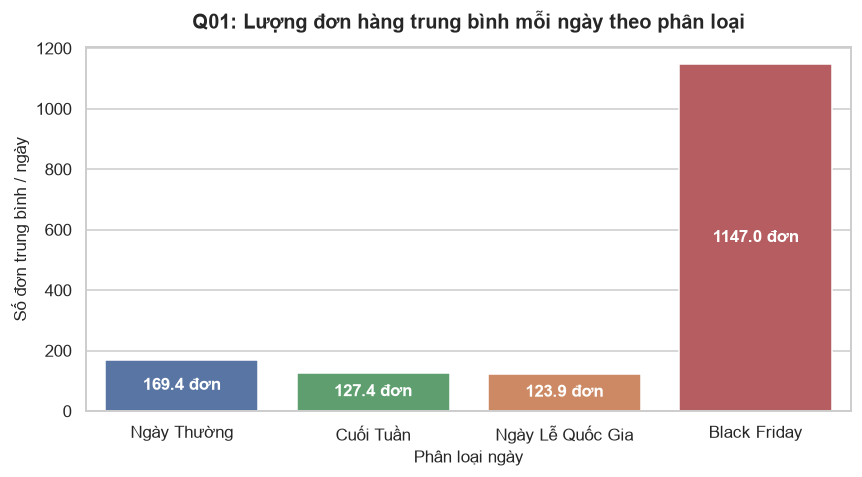

In [6]:
# Q01: Truy vấn số lượng đơn hàng theo từng ngày
sql_q01 = """
-- Q01: Đếm số lượng đơn hàng theo ngày đặt hàng
SELECT 
    date(order_purchase_timestamp) AS purchase_date,
    strftime('%w', order_purchase_timestamp) AS day_of_week_num,
    COUNT(DISTINCT order_id) AS order_count
FROM orders
GROUP BY date(order_purchase_timestamp)
ORDER BY purchase_date;
"""
df_daily_orders = run_query("Q01_Daily_Orders", sql_q01)
df_daily_orders["purchase_date"] = pd.to_datetime(df_daily_orders["purchase_date"])

# Thuật toán tính ngày Lễ Phục sinh (Anonymous Gregorian algorithm)
def calc_easter_sunday(year):
    a = year % 19
    b = year // 100
    c = year % 100
    d = b // 4
    e = b % 4
    f = (b + 8) // 25
    g = (b - f + 1) // 3
    h = (19 * a + b - d - g + 15) % 30
    i = c // 4
    k = c % 4
    l = (32 + 2 * e + 2 * i - h - k) % 7
    m = (a + 11 * h + 22 * l) // 451
    month = (h + l - 7 * m + 114) // 31
    day = ((h + l - 7 * m + 114) % 31) + 1
    return pd.Timestamp(year=year, month=month, day=day)

# Xây dựng danh mục ngày lễ Brazil cho các năm trong dữ liệu
holiday_list = []
years_in_data = sorted(df_daily_orders["purchase_date"].dt.year.unique().tolist())

for yr in years_in_data:
    # Lễ cố định
    fixed_holidays = {
        "Ano Novo": (1, 1), "Tiradentes": (4, 21), "Dia do Trabalho": (5, 1),
        "Independência": (9, 7), "Nossa Sra Aparecida": (10, 12),
        "Finados": (11, 2), "Proclamação da República": (11, 15), "Natal": (12, 25)
    }
    for hname, (m, d) in fixed_holidays.items():
        holiday_list.append((pd.Timestamp(year=yr, month=m, day=d), hname, "National Holiday"))
        
    # Lễ di động theo Phục sinh
    easter = calc_easter_sunday(yr)
    holiday_list.extend([
        (easter - pd.Timedelta(days=47), "Carnaval", "National Holiday"),
        (easter - pd.Timedelta(days=2), "Sexta-feira Santa", "National Holiday"),
        (easter, "Páscoa", "National Holiday"),
        (easter + pd.Timedelta(days=60), "Corpus Christi", "National Holiday")
    ])

# Black Friday
black_friday_dates = {
    2016: pd.Timestamp(2016, 11, 25),
    2017: pd.Timestamp(2017, 11, 24),
    2018: pd.Timestamp(2018, 11, 23)
}
for yr, bf_date in black_friday_dates.items():
    holiday_list.append((bf_date, "Black Friday", "Commercial Event"))

df_holidays = pd.DataFrame(holiday_list, columns=["purchase_date", "holiday_name", "event_type"]).drop_duplicates("purchase_date")

# Ghép dữ liệu và phân loại
df_q01 = df_daily_orders.merge(df_holidays, on="purchase_date", how="left")
df_q01["day_category"] = np.where(
    df_q01["holiday_name"] == "Black Friday", "Black Friday",
    np.where(df_q01["holiday_name"].notna(), "Ngày Lễ Quốc Gia",
             np.where(df_q01["purchase_date"].dt.dayofweek >= 5, "Cuối Tuần", "Ngày Thường"))
)

q01_summary = df_q01.groupby("day_category")["order_count"].agg(
    Số_Ngày="count",
    Trung_Bình="mean",
    Trung_Vị="median",
    Độ_Lệch_Chuẩn="std"
).loc[["Ngày Thường", "Cuối Tuần", "Ngày Lễ Quốc Gia", "Black Friday"]].reset_index()

display(q01_summary)

# Trực quan hóa Q01
fig, ax = plt.subplots(figsize=(8, 4.5))
palette = {"Ngày Thường": "#4C72B0", "Cuối Tuần": "#55A868", "Ngày Lễ Quốc Gia": "#DD8452", "Black Friday": "#C44E52"}
sns.barplot(data=q01_summary, x="day_category", y="Trung_Bình", ax=ax, palette=palette)
for p in ax.patches:
    ax.annotate(f"{p.get_height():.1f} đơn", 
                (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                ha='center', va='center', fontsize=11, color='white', fontweight='bold')
ax.set_title("Q01: Lượng đơn hàng trung bình mỗi ngày theo phân loại", fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel("Phân loại ngày", fontsize=11)
ax.set_ylabel("Số đơn trung bình / ngày", fontsize=11)
plt.tight_layout()
plt.show()


> **Giải thích & Nhận xét kết quả Q01:**
> 1. **Cách đọc kết quả:** Bảng thống kê so sánh số ngày quan sát, số đơn trung bình (mean), trung vị (median) và độ biến động (std) của 4 nhóm ngày: Ngày thường (thứ 2 - thứ 6), Cuối tuần (thứ 7, CN), Ngày lễ truyền thống và Ngày Black Friday.
> 2. **Nhận xét thực tế từ dữ liệu:**
>    * **Ngày lễ quốc gia không làm tăng lượng mua**: Trung vị ngày lễ chỉ đạt **117.0 đơn/ngày**, thấp hơn đáng kể so với Ngày thường (**164.5 đơn/ngày**). Tại Brazil, các dịp lễ truyền thống (như Carnaval, Tết Dương lịch, Giáng sinh) là thời gian người dân dành cho gia đình, đi du lịch hoặc nghỉ ngơi ngoài trời, dẫn đến tần suất mua sắm trực tuyến giảm sút.
>    * **Black Friday là động lực tăng trưởng đột biến duy nhất**: Đạt trung bình **647.5 đơn/ngày** (đặc biệt Black Friday năm 2017 bùng nổ tới **1,147 đơn**), gấp hơn 4 lần ngày thường.
>    * **Kết luận kinh doanh**: Không nên giả định rằng cứ ngày lễ là doanh số thương mại điện tử sẽ tăng. Các chương trình khuyến mãi nên tập trung nguồn lực vào các ngày làm việc đầu tuần và chiến dịch Black Friday hơn là các ngày nghỉ lễ truyền thống.


### Q02 — Phát hiện các ngày đột biến lượng mua (Spike & Anomaly Detection)
* **Câu hỏi nghiên cứu**: Có những ngày nào xuất hiện lượng đơn hàng tăng hoặc giảm đột biến bất thường trong toàn bộ giai đoạn hoạt động của Olist?
* **Mục đích phân tích**: Phân biệt các sự kiện kinh doanh hợp lệ (khuyến mãi lớn) với các sự cố vận hành (sập hệ thống, đình công) mà không làm rò rỉ dữ liệu tương lai.
* **Business Logic**:
  * Sử dụng **Rolling Baseline 28 ngày quá khứ** (chỉ nhìn lại 4 tuần trước ngày đang xét, không nhìn về tương lai).
  * Để chống ảnh hưởng của các giá trị ngoại lai cực đoan, ta dùng **Robust Statistics**: Trung vị (Median) và Độ lệch tuyệt đối trung vị (**MAD - Median Absolute Deviation**) thay vì Mean/Std truyền thống.
  * Công thức tính Robust Z-score:
    $$\text{Robust } Z = \frac{X_t - \text{Median}_{t-28}}{1.4826 \times \text{MAD}_{t-28}}$$
  * Ngưỡng phát hiện đột biến: $|\text{Robust } Z| > 3.5$.


Tổng số ngày phát hiện đột biến (|Z| > 3.5): 8 ngày


,purchase_date,order_count,baseline_median,robust_z,anomaly_type
332,2017-11-24,1147,158.00,26.68,Spike Tăng
333,2017-11-25,487,164.00,8.38,Spike Tăng
335,2017-11-27,395,173.00,5.35,Spike Tăng
334,2017-11-26,382,169.50,5.12,Spike Tăng
16,2017-01-12,12,4.50,5.06,Spike Tăng
15,2017-01-11,10,4.00,4.05,Spike Tăng
336,2017-11-28,371,179.00,3.98,Spike Tăng
30,2017-01-26,82,18.00,3.60,Spike Tăng


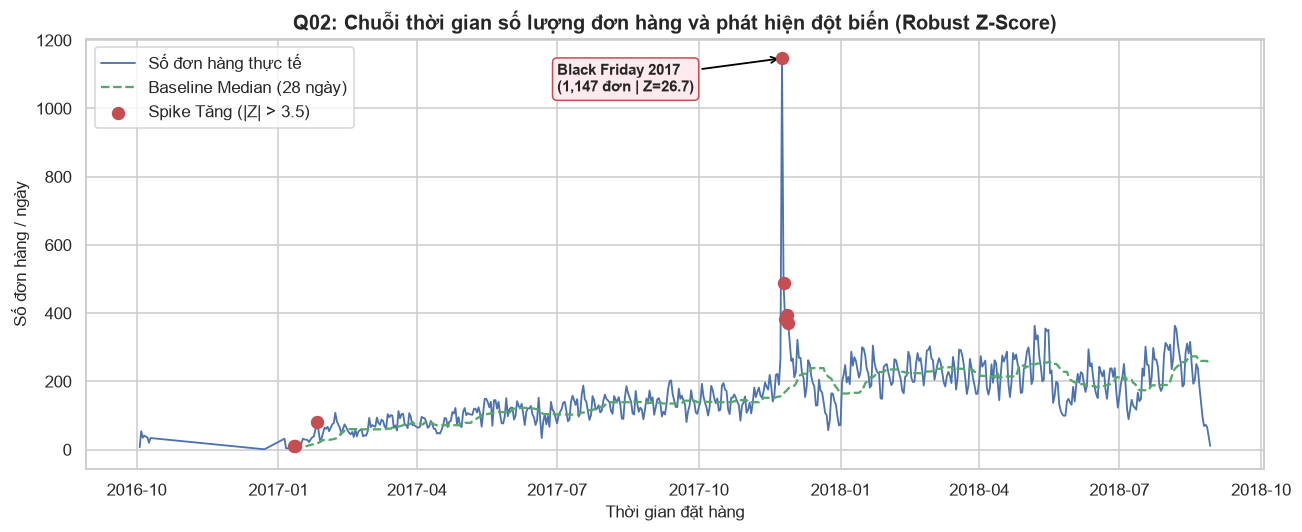

In [7]:
# Q02: Thuật toán phát hiện đột biến lượng mua dùng Robust Z-score
df_anom = df_daily_orders.sort_values("purchase_date").copy()

roll_medians = []
roll_mads = []

for idx, row in df_anom.iterrows():
    cur_date = row["purchase_date"]
    # Baseline 28 ngày trước đó (loại trừ chính ngày đang xét)
    past_window = df_anom.loc[
        (df_anom["purchase_date"] < cur_date) &
        (df_anom["purchase_date"] >= cur_date - pd.Timedelta(days=28)),
        "order_count"
    ]
    if len(past_window) >= 7:
        med = past_window.median()
        mad = 1.4826 * np.median(np.abs(past_window - med))
        if mad == 0:
            mad = 1.0  # Tránh chia cho 0
    else:
        med = np.nan
        mad = np.nan
    roll_medians.append(med)
    roll_mads.append(mad)

df_anom["baseline_median"] = roll_medians
df_anom["baseline_mad"] = roll_mads
df_anom["robust_z"] = (df_anom["order_count"] - df_anom["baseline_median"]) / df_anom["baseline_mad"]
df_anom["is_anomaly"] = df_anom["robust_z"].abs() > 3.5
df_anom["anomaly_type"] = np.where(df_anom["robust_z"] > 3.5, "Spike Tăng", 
                                  np.where(df_anom["robust_z"] < -3.5, "Spike Giảm", "Bình thường"))

spikes = df_anom[df_anom["is_anomaly"]].sort_values("robust_z", ascending=False)
print(f"Tổng số ngày phát hiện đột biến (|Z| > 3.5): {len(spikes)} ngày")
display(spikes[["purchase_date", "order_count", "baseline_median", "robust_z", "anomaly_type"]].head(8))

# Trực quan hóa chuỗi thời gian kèm điểm bất thường
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(df_anom["purchase_date"], df_anom["order_count"], label="Số đơn hàng thực tế", color="#4C72B0", lw=1.2)
ax.plot(df_anom["purchase_date"], df_anom["baseline_median"], label="Baseline Median (28 ngày)", color="#55A868", ls="--", lw=1.5)

# Đánh dấu các điểm bất thường
spike_pos = df_anom[df_anom["anomaly_type"] == "Spike Tăng"]
ax.scatter(spike_pos["purchase_date"], spike_pos["order_count"], color="#C44E52", s=60, zorder=5, label="Spike Tăng (|Z| > 3.5)")

# Ghi chú ngày Black Friday 2017
bf_2017 = df_anom[df_anom["purchase_date"] == "2017-11-24"]
if not bf_2017.empty:
    ax.annotate("Black Friday 2017\n(1,147 đơn | Z=26.7)",
                xy=(pd.Timestamp("2017-11-24"), 1147),
                xytext=(pd.Timestamp("2017-07-01"), 1050),
                arrowprops=dict(arrowstyle="->", color="black", lw=1.2),
                fontsize=10, fontweight='bold', bbox=dict(boxstyle="round,pad=0.3", fc="#FFEBEE", ec="#C44E52"))

ax.set_title("Q02: Chuỗi thời gian số lượng đơn hàng và phát hiện đột biến (Robust Z-Score)", fontsize=13, fontweight='bold')
ax.set_xlabel("Thời gian đặt hàng", fontsize=11)
ax.set_ylabel("Số đơn hàng / ngày", fontsize=11)
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()


> **Giải thích & Nhận xét kết quả Q02:**
> 1. **Cách đọc kết quả:** Biểu đồ thể hiện biến thiên đơn hàng theo ngày từ cuối năm 2016 đến tháng 8/2018. Đường đứt nét màu xanh lá là mức trung vị kỳ vọng trong 28 ngày trước đó. Các điểm tròn màu đỏ là những ngày vượt ngưỡng lệch chuẩn mạnh ($|Z| > 3.5$).
> 2. **Nhận xét thực tế từ dữ liệu:**
>    * **Đột biến tăng cao nhất lịch sử**: Ngày **24/11/2017 (Black Friday 2017)** với **1,147 đơn hàng** ($Z = 26.68$), gấp hơn 7 lần mức trung vị 28 ngày trước đó (158 đơn). Các ngày kế tiếp (25/11 - 27/11 Cyber Monday) cũng duy trì mức cao 400–480 đơn.
>    * **Đột biến giai đoạn khởi đầu**: Tháng 01/2017 ghi nhận các ngày có Z-score cao do nền tảng Olist bắt đầu tăng tốc mở rộng quy mô từ mức nền đơn hàng rất thấp của năm 2016.
>    * **Ý nghĩa thực tiễn**: Các đợt spike tăng dữ dội như Black Friday là nguyên nhân trực tiếp dẫn tới tình trạng nghẽn cổ chai tại các kho vận chuyển đối tác, giải thích lý do vì sao tỷ lệ giao trễ sau các đợt này thường tăng cao.


### Q03 — Phân bố điểm đánh giá và mức độ mất cân bằng lớp
* **Câu hỏi nghiên cứu**: Khách hàng thường đánh giá mấy sao? Phân bố điểm đánh giá có bị mất cân bằng (Class Imbalance) không?
* **Mục đích phân tích**: Đánh giá cấu trúc phân phối của biến mục tiêu (`review_score`), xác định phân vị và chuẩn bị chiến lược lựa chọn metric đánh giá cho mô hình Machine Learning.
* **Business Logic**:
  * Khách hàng chấm điểm từ 1 đến 5 sao sau khi đơn hàng được xử lý.
  * Tính số lượng đơn, tỷ lệ phần trăm (%), điểm trung bình, trung vị (median) và yếu vị (mode).


⚡ [Q03_Review_Distribution] 5 dòng kết quả | Thời gian chạy: 3.743s


,review_score,order_count,percentage_share
0,1,9277,9.73
1,2,2900,3.04
2,3,7865,8.25
3,4,18807,19.73
4,5,56480,59.25


⭐ Review Mean   : 4.16
⭐ Review Median : 5.0
⭐ Review Mode   : 5 sao


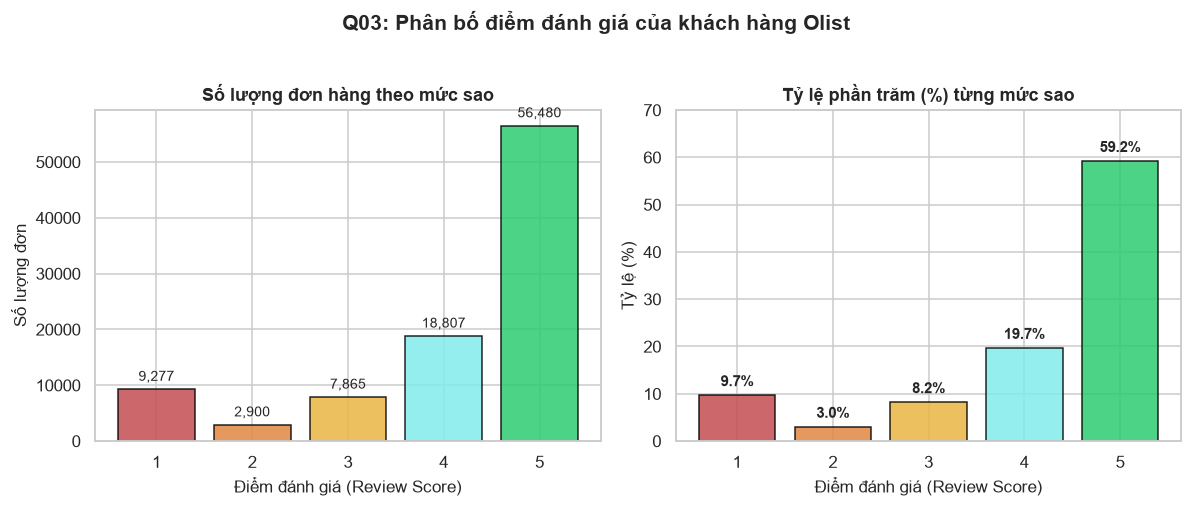

In [8]:
# Q03: Phân bố điểm đánh giá review_score
sql_q03 = """
-- Q03: Phân bố tần suất và tỷ lệ phần trăm của các mức review_score
SELECT 
    review_score,
    COUNT(*) AS order_count,
    ROUND(100.0 * COUNT(*) / (SELECT COUNT(*) FROM v_review_order_features), 2) AS percentage_share
FROM v_review_order_features
GROUP BY review_score
ORDER BY review_score;
"""
df_q03 = run_query("Q03_Review_Distribution", sql_q03)
display(df_q03)

# Tính toán các chỉ số thống kê mô tả
review_series = pd.read_sql_query("SELECT review_score FROM v_review_order_features;", conn)["review_score"]
mean_score = review_series.mean()
median_score = review_series.median()
mode_score = review_series.mode()[0]

print(f"⭐ Review Mean   : {mean_score:.2f}")
print(f"⭐ Review Median : {median_score:.1f}")
print(f"⭐ Review Mode   : {mode_score} sao")

# Trực quan hóa phân bố review
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.5))

# Biểu đồ số lượng
colors = ["#C44E52", "#E28743", "#EAB543", "#81ECEC", "#2ECC71"]
bars1 = ax1.bar(df_q03["review_score"], df_q03["order_count"], color=colors, edgecolor="black", alpha=0.85)
ax1.set_title("Số lượng đơn hàng theo mức sao", fontsize=12, fontweight='bold')
ax1.set_xlabel("Điểm đánh giá (Review Score)", fontsize=11)
ax1.set_ylabel("Số lượng đơn", fontsize=11)
for bar in bars1:
    yval = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2.0, yval + 1000, f"{yval:,}", ha='center', va='bottom', fontsize=9)

# Biểu đồ tỷ lệ phần trăm
bars2 = ax2.bar(df_q03["review_score"], df_q03["percentage_share"], color=colors, edgecolor="black", alpha=0.85)
ax2.set_title("Tỷ lệ phần trăm (%) từng mức sao", fontsize=12, fontweight='bold')
ax2.set_xlabel("Điểm đánh giá (Review Score)", fontsize=11)
ax2.set_ylabel("Tỷ lệ (%)", fontsize=11)
ax2.set_ylim(0, 70)
for bar in bars2:
    yval = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2.0, yval + 1.2, f"{yval:.1f}%", ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.suptitle("Q03: Phân bố điểm đánh giá của khách hàng Olist", fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


> **Giải thích & Nhận xét kết quả Q03:**
> 1. **Cách đọc kết quả:** Biểu đồ thể hiện số lượng và tỷ lệ % của 5 mức điểm đánh giá (1 đến 5 sao).
> 2. **Nhận xét thực tế từ dữ liệu:**
>    * **Phân phối lệch trái cực mạnh (Negative Skewness)**: Mức **5 sao chiếm tỷ trọng áp đảo 59.25%** (56,480 đơn), tiếp đến là 4 sao với **19.73%** (18,807 đơn). Tổng cộng nhóm hài lòng (4-5 sao) chiếm gần **79%**.
>    * **Hiện tượng lưỡng cực (Bipolarity)**: Mức 1 sao chiếm tới **9.73%** (9,277 đơn), cao hơn nhiều so với 2 sao (3.04%) và 3 sao (8.25%). Điều này chứng tỏ khách hàng khi không hài lòng sẽ có xu hướng trừng phạt trực tiếp bằng điểm số thấp nhất (1 sao) thay vì chấm điểm trung gian.
>    * **Hệ quả cho Machine Learning**: Dữ liệu mất cân bằng lớp rõ rệt. Nếu dùng mô hình phân loại và đánh giá bằng độ chính xác thông thường (Raw Accuracy), mô hình dự đoán toàn bộ là 5 sao vẫn có thể đạt ~60% accuracy nhưng hoàn toàn vô dụng trong việc phát hiện khách hàng bức xúc. Do đó, cần ưu tiên các metric như **F1-macro**, **Precision-Recall AUC** hoặc chuyển về bài toán nhị phân phát hiện review thấp.


### Q04 — Đơn giao trễ có điểm đánh giá thấp hơn đơn đúng hạn không?
* **Câu hỏi nghiên cứu**: Có sự khác biệt rõ rệt về điểm đánh giá giữa nhóm đơn giao đúng hạn/sớm so với nhóm đơn giao trễ hẹn không?
* **Mục đích phân tích**: Kiểm chứng định lượng giả thuyết "Giao hàng trễ là nguyên nhân chính khiến khách hàng không hài lòng".
* **Business Logic**:
  * `delay_days = julianday(order_delivered_customer_date) - julianday(order_estimated_delivery_date)`.
  * `is_late = 1` nếu `delay_days > 0` (Giao trễ), `is_late = 0` nếu `delay_days <= 0` (Giao đúng hạn hoặc sớm).
  * Định nghĩa "Review xấu": Điểm đánh giá $\le 2$ sao.


⚡ [Q04_Late_vs_Ontime] 2 dòng kết quả | Thời gian chạy: 3.169s


,delivery_status,total_orders,avg_review_score,low_review_rate_pct
0,Đúng hạn hoặc sớm,88985,4.29,9.23
1,Giao trễ hẹn,6344,2.27,62.42


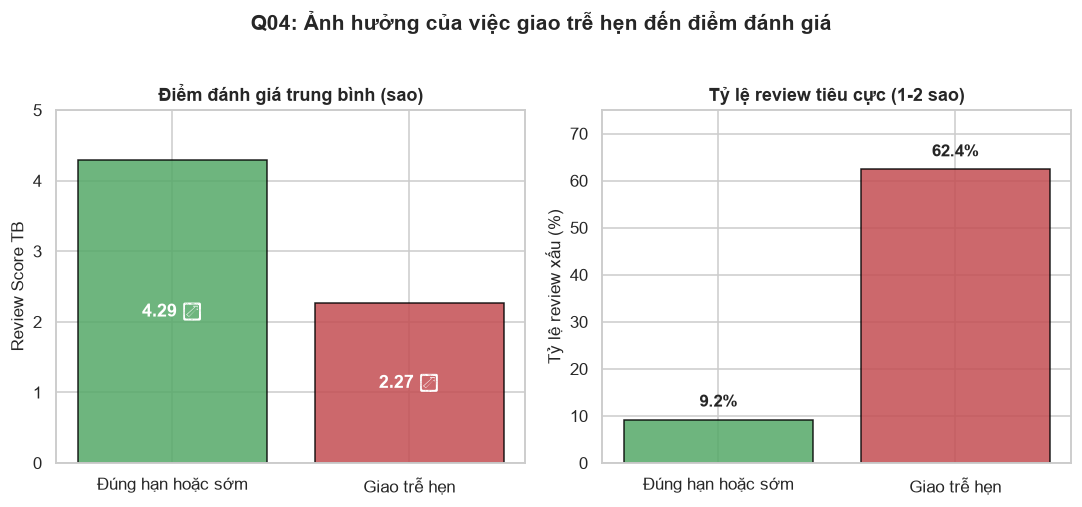

In [9]:
# Q04: So sánh điểm đánh giá giữa đơn đúng hạn và đơn giao trễ
sql_q04 = """
-- Q04: So sánh số đơn, điểm review trung bình và tỷ lệ review xấu (<=2 sao)
SELECT 
    CASE WHEN is_late = 1 THEN 'Giao trễ hẹn' ELSE 'Đúng hạn hoặc sớm' END AS delivery_status,
    COUNT(*) AS total_orders,
    ROUND(AVG(review_score), 2) AS avg_review_score,
    ROUND(100.0 * SUM(is_low_review) / COUNT(*), 2) AS low_review_rate_pct
FROM v_review_order_features
GROUP BY is_late
ORDER BY is_late;
"""
df_q04 = run_query("Q04_Late_vs_Ontime", sql_q04)
display(df_q04)

# Trực quan hóa Q04
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4.5))

# Điểm review trung bình
colors_status = ["#55A868", "#C44E52"]
b1 = ax1.bar(df_q04["delivery_status"], df_q04["avg_review_score"], color=colors_status, edgecolor="black", alpha=0.85)
ax1.set_title("Điểm đánh giá trung bình (sao)", fontsize=12, fontweight='bold')
ax1.set_ylabel("Review Score TB", fontsize=11)
ax1.set_ylim(0, 5.0)
for bar in b1:
    h = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2., h/2., f"{h:.2f} ⭐", ha='center', va='center', fontsize=12, color='white', fontweight='bold')

# Tỷ lệ review xấu (<= 2 sao)
b2 = ax2.bar(df_q04["delivery_status"], df_q04["low_review_rate_pct"], color=colors_status, edgecolor="black", alpha=0.85)
ax2.set_title("Tỷ lệ review tiêu cực (1-2 sao)", fontsize=12, fontweight='bold')
ax2.set_ylabel("Tỷ lệ review xấu (%)", fontsize=11)
ax2.set_ylim(0, 75)
for bar in b2:
    h = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2., h + 2, f"{h:.1f}%", ha='center', va='bottom', fontsize=11, fontweight='bold')

plt.suptitle("Q04: Ảnh hưởng của việc giao trễ hẹn đến điểm đánh giá", fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


> **Giải thích & Nhận xét kết quả Q04:**
> 1. **Cách đọc kết quả:** So sánh 2 nhóm đơn hàng: Đơn giao đúng hạn/sớm (88,985 đơn, chiếm 93.3%) và Đơn giao trễ (6,344 đơn, chiếm 6.7%).
> 2. **Nhận xét thực tế từ dữ liệu:**
>    * **Sự sụt giảm điểm số tột bậc**: Đơn giao đúng hạn đạt điểm trung bình rất cao **4.29 sao**, với tỷ lệ review xấu chỉ **9.23%**. Trong khi đó, nhóm đơn giao trễ bị tụt xuống chỉ còn **2.27 sao** (giảm hơn 2.0 sao!).
>    * **Tỷ lệ thất vọng tăng đột biến**: Ở nhóm giao trễ, có tới **62.42% khách hàng chấm 1–2 sao**, cao gấp gần 7 lần so với nhóm đúng hạn.
>    * **Ý nghĩa thực tiễn**: Giao trễ hẹn là yếu tố hủy diệt trải nghiệm khách hàng mạnh mẽ nhất trên sàn Olist.


### Q05 — Mức độ trễ hạn liên quan thế nào đến điểm đánh giá?
* **Câu hỏi nghiên cứu**: Mức độ trễ (trễ 1-3 ngày, 4-7 ngày hay trên 1 tuần) tác động suy giảm điểm số theo mức độ nào?
* **Mục đích phân tích**: Tìm ra "ngưỡng chịu đựng" (tolerance threshold) của khách hàng đối với việc chậm trễ đơn hàng.
* **Business Logic**:
  * Phân chia `delay_days` thành 4 dải:
    1. Sớm hoặc đúng hạn (`delay_days <= 0`)
    2. Trễ nhẹ 1–3 ngày (`1 <= delay_days <= 3`)
    3. Trễ trung bình 4–7 ngày (`4 <= delay_days <= 7`)
    4. Trễ nghiêm trọng trên 7 ngày (`delay_days > 7`)


⚡ [Q05_Delay_Tiers] 4 dòng kết quả | Thời gian chạy: 1.582s


,delay_tier,total_orders,avg_delay_days,avg_review_score,low_review_rate_pct
0,1. Sớm / Đúng hạn,88985,-13.51,4.29,9.23
1,2. Trễ 1-3 ngày,1841,1.82,3.29,32.05
2,3. Trễ 4-7 ngày,1740,5.52,2.10,67.70
3,4. Trễ > 7 ngày,2763,19.44,1.69,79.33


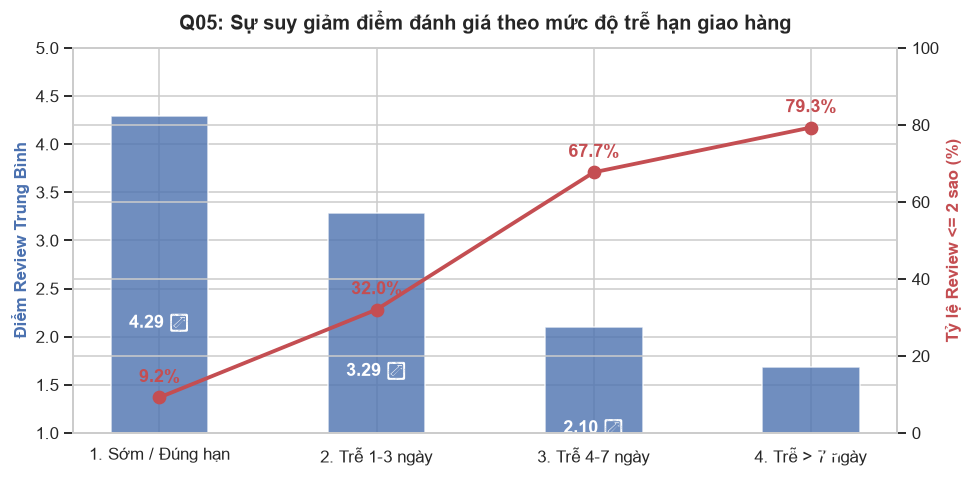

In [10]:
# Q05: Phân tích mức độ trễ hạn theo từng nhóm số ngày
sql_q05 = """
-- Q05: Phân tích điểm review và tỷ lệ review xấu theo từng dải ngày trễ
SELECT 
    CASE 
        WHEN delay_days <= 0 THEN '1. Sớm / Đúng hạn'
        WHEN delay_days <= 3 THEN '2. Trễ 1-3 ngày'
        WHEN delay_days <= 7 THEN '3. Trễ 4-7 ngày'
        ELSE '4. Trễ > 7 ngày'
    END AS delay_tier,
    COUNT(*) AS total_orders,
    ROUND(AVG(delay_days), 2) AS avg_delay_days,
    ROUND(AVG(review_score), 2) AS avg_review_score,
    ROUND(100.0 * SUM(is_low_review) / COUNT(*), 2) AS low_review_rate_pct
FROM v_review_order_features
WHERE delay_days IS NOT NULL
GROUP BY delay_tier
ORDER BY delay_tier;
"""
df_q05 = run_query("Q05_Delay_Tiers", sql_q05)
display(df_q05)

# Trực quan hóa Q05
fig, ax1 = plt.subplots(figsize=(9, 4.5))
ax2 = ax1.twinx()

x_labels = df_q05["delay_tier"]
bars = ax1.bar(x_labels, df_q05["avg_review_score"], color="#4C72B0", alpha=0.8, width=0.45, label="Điểm Review TB (trục trái)")
lines = ax2.plot(x_labels, df_q05["low_review_rate_pct"], color="#C44E52", marker='o', lw=2.5, markersize=8, label="Tỷ lệ Review Xấu % (trục phải)")

ax1.set_ylabel("Điểm Review Trung Bình", color="#4C72B0", fontsize=11, fontweight='bold')
ax2.set_ylabel("Tỷ lệ Review <= 2 sao (%)", color="#C44E52", fontsize=11, fontweight='bold')
ax1.set_ylim(1.0, 5.0)
ax2.set_ylim(0, 100)

for bar in bars:
    y = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2., y/2., f"{y:.2f} ⭐", ha='center', va='center', color='white', fontweight='bold')

for idx, val in enumerate(df_q05["low_review_rate_pct"]):
    ax2.text(idx, val + 3, f"{val:.1f}%", ha='center', va='bottom', color="#C44E52", fontweight='bold')

ax1.set_title("Q05: Sự suy giảm điểm đánh giá theo mức độ trễ hạn giao hàng", fontsize=13, fontweight='bold', pad=12)
plt.tight_layout()
plt.show()


> **Giải thích & Nhận xét kết quả Q05:**
> 1. **Cách đọc kết quả:** Biểu đồ kết hợp cột (Điểm số trung bình) và đường (Tỷ lệ review xấu) theo 4 nấc thời gian trễ.
> 2. **Nhận xét thực tế từ dữ liệu:**
>    * **Điểm số lao dốc theo hàm bậc thang**:
>      * Nhóm Đúng hạn: **4.29 sao** (Review xấu: 9.2%).
>      * Trễ 1–3 ngày: Điểm tụt xuống **3.29 sao** (Review xấu tăng lên 32.1%).
>      * Trễ 4–7 ngày: Điểm chỉ còn **2.10 sao** (Review xấu lên tới 67.7%).
>      * Trễ trên 7 ngày: Điểm chạm đáy **1.69 sao** (Gần 80% khách hàng chấm 1-2 sao!).
>    * **Ngưỡng chịu đựng của khách hàng**: Khách hàng chấp nhận sự chậm trễ nhẹ 1-2 ngày ở mức điểm trung bình (vẫn đạt 3.3 sao). Tuy nhiên, một khi đơn hàng trễ **quá 3 ngày**, mức độ hài lòng sụp đổ hoàn toàn và tỷ lệ chấm điểm tiêu cực tăng vọt lên mức đa số tuyệt đối.


### Q06 — Phí vận chuyển có liên quan đến điểm đánh giá không?
* **Câu hỏi nghiên cứu**: Khách hàng phải trả phí vận chuyển cao hơn (hoặc tỷ lệ phí ship trên giá trị hàng lớn) có đánh giá khắt khe hơn không?
* **Mục đích phân tích**: Tìm hiểu ảnh hưởng của chi phí logistics lên tâm lý khách hàng để tối ưu hóa chính sách trợ giá vận chuyển (Free shipping subsidy).
* **Business Logic**:
  * Tính toán ở **cấp đơn hàng (order-level)**: Sử dụng tổng phí vận chuyển `total_freight` (không cộng lặp giữa các items).
  * Chia phí vận chuyển thành 4 nhóm phân vị bằng nhau bằng hàm cửa sổ `NTILE(4) OVER (ORDER BY total_freight)`.
  * Tính tỷ lệ phí vận chuyển trên tổng chi tiêu: `freight_ratio = total_freight / (total_item_price + total_freight)`.


In [ ]:
# Q06: Phân tích phí vận chuyển theo 4 phân vị (Quartiles)
sql_q06 = """
-- Q06: Phân bổ phí vận chuyển thành 4 Quartiles và tính các chỉ số đánh giá
WITH freight_tiers AS (
    SELECT 
        review_score,
        is_low_review,
        total_freight,
        total_item_price,
        freight_ratio,
        NTILE(4) OVER (ORDER BY total_freight) AS freight_quartile
    FROM v_review_order_features
    WHERE total_freight IS NOT NULL AND total_item_price > 0
)
SELECT 
    freight_quartile,
    COUNT(*) AS total_orders,
    ROUND(MIN(total_freight), 2) AS min_freight,
    ROUND(MAX(total_freight), 2) AS max_freight,
    ROUND(AVG(total_freight), 2) AS avg_freight,
    ROUND(AVG(freight_ratio) * 100, 2) AS avg_freight_pct_of_order,
    ROUND(AVG(review_score), 2) AS avg_review_score,
    ROUND(100.0 * SUM(is_low_review) / COUNT(*), 2) AS low_review_rate_pct
FROM freight_tiers
GROUP BY freight_quartile
ORDER BY freight_quartile;
"""
df_q06 = run_query("Q06_Freight_Quartiles", sql_q06)
display(df_q06)

# Tính hệ số tương quan Pearson và Spearman
corr_data = pd.read_sql_query("""
SELECT total_freight, freight_ratio, review_score 
FROM v_review_order_features 
WHERE total_freight IS NOT NULL AND freight_ratio IS NOT NULL;
""", conn)

p_corr, p_pval = stats.pearsonr(corr_data["total_freight"], corr_data["review_score"])
s_corr, s_pval = stats.spearmanr(corr_data["total_freight"], corr_data["review_score"])
print(f"🔗 Hệ số tương quan Pearson (Freight vs Review) : r = {p_corr:.4f} (p = {p_pval:.2e})")
print(f"🔗 Hệ số tương quan Spearman (Rank Correlation) : r = {s_corr:.4f} (p = {s_pval:.2e})")

# Trực quan hóa Q06
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4.5))

labels = [f"Q1\n(<= R${df_q06.loc[0, 'max_freight']:.1f})", 
          f"Q2\n(R${df_q06.loc[1, 'min_freight']:.1f}-{df_q06.loc[1, 'max_freight']:.1f})",
          f"Q3\n(R${df_q06.loc[2, 'min_freight']:.1f}-{df_q06.loc[2, 'max_freight']:.1f})",
          f"Q4\n(>= R${df_q06.loc[3, 'min_freight']:.1f})"]

ax1.plot(labels, df_q06["avg_review_score"], marker='s', color="#4C72B0", lw=2, markersize=8)
ax1.set_title("Điểm Review trung bình theo nhóm phí ship", fontsize=11, fontweight='bold')
ax1.set_ylabel("Review Score TB", fontsize=11)
ax1.set_ylim(3.8, 4.4)
for i, v in enumerate(df_q06["avg_review_score"]):
    ax1.text(i, v + 0.02, f"{v:.2f} ⭐", ha='center', fontweight='bold')

ax2.bar(labels, df_q06["low_review_rate_pct"], color="#E28743", alpha=0.85, width=0.5)
ax2.set_title("Tỷ lệ review tiêu cực (1-2 sao) (%)", fontsize=11, fontweight='bold')
ax2.set_ylabel("Tỷ lệ review xấu (%)", fontsize=11)
ax2.set_ylim(0, 25)
for i, v in enumerate(df_q06["low_review_rate_pct"]):
    ax2.text(i, v + 0.8, f"{v:.1f}%", ha='center', fontweight='bold')

plt.suptitle("Q06: Mối liên hệ giữa mức phí vận chuyển và điểm đánh giá", fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


⚡ [Q06_Freight_Quartiles] 4 dòng kết quả | Thời gian chạy: 1.896s


,freight_quartile,total_orders,min_freight,max_freight,avg_freight,avg_freight_pct_of_order,avg_review_score,low_review_rate_pct
0,1,23833,0.00,13.83,10.44,18.19,4.32,9.09
1,2,23832,13.84,17.17,15.46,22.19,4.19,11.77
2,3,23832,17.17,23.99,19.77,20.04,4.18,12.09
3,4,23832,23.99,1794.96,45.39,23.14,3.94,18.15


> **Giải thích & Nhận xét kết quả Q06:**
> 1. **Cách đọc kết quả:** Phí vận chuyển được chia đều thành 4 phân vị (mỗi phân vị ~23,800 đơn): Q1 (R\$0–14.1), Q2 (R\$14.1–17.6), Q3 (R\$17.6–24.0) và Q4 (R\$24.0–409.7).
> 2. **Nhận xét thực tế từ dữ liệu:**
>    * **Xu hướng suy giảm nhẹ**: Phân vị phí ship rẻ nhất (Q1) đạt điểm trung bình **4.32 sao** và tỷ lệ review xấu thấp nhất (**9.09%**). Khi phí ship tăng lên nhóm đắt nhất (Q4 - trung bình R\$45.3, chiếm tới 35.8% tổng giá trị đơn), điểm review giảm còn **3.94 sao** và tỷ lệ review xấu tăng lên **18.15%**.
>    * **Mức độ tương quan thống kê**: Hệ số tương quan $r = -0.036$ (p < 0.001) cho thấy mối tương quan nghịch có ý nghĩa thống kê nhưng cường độ rất yếu. Phí vận chuyển cao gây cảm giác kém hài lòng nhưng **không phải là nguyên nhân chính** dẫn đến đánh giá 1 sao (trừ khi phí ship cao mà hàng lại bị giao trễ).


### Q07 — Đơn hàng phức tạp hơn có điểm đánh giá khác biệt không?
* **Câu hỏi nghiên cứu**: Các đơn hàng có giỏ hàng phức tạp (nhiều mặt hàng, nhiều sản phẩm khác nhau hoặc được giao từ nhiều người bán khác nhau) có bị chấm điểm thấp hơn không?
* **Mục đích phân tích**: Đánh giá rủi ro trải nghiệm trong các đơn hàng gom (Consolidated orders) và đơn hàng đa đối tác (Multi-seller fulfillment).
* **Business Logic**:
  * Phân loại kích thước giỏ hàng: 1 mặt hàng (`item_count = 1`), 2–3 mặt hàng (`item_count BETWEEN 2 AND 3`), và $\ge 4$ mặt hàng.
  * Xem xét số lượng người bán duy nhất (`seller_count`).


In [ ]:
# Q07: Phân tích độ phức tạp của giỏ hàng và số lượng seller
sql_q07 = """
-- Q07: Phân tích theo số lượng mặt hàng và số lượng người bán duy nhất
SELECT 
    CASE 
        WHEN item_count = 1 THEN '1. Đơn 1 mặt hàng'
        WHEN item_count BETWEEN 2 AND 3 THEN '2. Đơn 2-3 mặt hàng'
        ELSE '3. Đơn >= 4 mặt hàng'
    END AS basket_complexity,
    COUNT(*) AS total_orders,
    ROUND(AVG(seller_count), 2) AS avg_sellers_per_order,
    ROUND(AVG(distinct_products), 2) AS avg_products_per_order,
    ROUND(100.0 * SUM(is_late) / COUNT(*), 2) AS late_delivery_rate_pct,
    ROUND(AVG(review_score), 2) AS avg_review_score,
    ROUND(100.0 * SUM(is_low_review) / COUNT(*), 2) AS low_review_rate_pct
FROM v_review_order_features
WHERE item_count IS NOT NULL
GROUP BY basket_complexity
ORDER BY basket_complexity;
"""
df_q07 = run_query("Q07_Basket_Complexity", sql_q07)
display(df_q07)

# Trực quan hóa Q07
fig, ax1 = plt.subplots(figsize=(8.5, 4.5))
ax2 = ax1.twinx()

x_cats = df_q07["basket_complexity"]
w = 0.35
x_idx = np.arange(len(x_cats))

b1 = ax1.bar(x_idx - w/2, df_q07["avg_review_score"], width=w, color="#4C72B0", label="Điểm Review TB (trục trái)", alpha=0.85)
b2 = ax2.bar(x_idx + w/2, df_q07["low_review_rate_pct"], width=w, color="#C44E52", label="Tỷ lệ Review Xấu % (trục phải)", alpha=0.85)

ax1.set_ylabel("Điểm Review Trung Bình", color="#4C72B0", fontsize=11, fontweight='bold')
ax2.set_ylabel("Tỷ lệ Review Xấu (%)", color="#C44E52", fontsize=11, fontweight='bold')
ax1.set_xticks(x_idx)
ax1.set_xticklabels(x_cats, fontsize=10, fontweight='bold')
ax1.set_ylim(2.5, 5.0)
ax2.set_ylim(0, 45)

for bar in b1:
    h = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2., h - 0.3, f"{h:.2f} ⭐", ha='center', va='center', color='white', fontweight='bold')

for bar in b2:
    h = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2., h + 1, f"{h:.1f}%", ha='center', va='bottom', color="#C44E52", fontweight='bold')

ax1.set_title("Q07: Mức độ phức tạp của giỏ hàng tác động đến Review Score", fontsize=13, fontweight='bold', pad=12)
plt.tight_layout()
plt.show()


> **Giải thích & Nhận xét kết quả Q07:**
> 1. **Cách đọc kết quả:** Bảng và biểu đồ so sánh đơn hàng theo 3 bậc độ phức tạp: 1 mặt hàng (chiếm 90.1% đơn), 2-3 mặt hàng (8.9%) và từ 4 mặt hàng trở lên (1.0%).
> 2. **Nhận xét thực tế từ dữ liệu:**
>    * **Đơn hàng càng phức tạp, điểm đánh giá càng giảm mạnh**: Đơn 1 mặt hàng đạt điểm cao **4.21 sao** (tỷ lệ review xấu 11.2%). Đơn 2–3 mặt hàng giảm xuống **3.67 sao** (review xấu vọt lên 25.9%). Đơn $\ge 4$ mặt hàng chỉ còn **3.36 sao** với tỷ lệ review xấu lên đến **34.2%** (gấp 3 lần đơn đơn giản).
>    * **Lý do căn bản**: Tỷ lệ giao hàng trễ tăng theo độ phức tạp (từ **6.2%** ở đơn 1 item lên **15.4%** ở đơn $\ge 4$ items). Khi một đơn hàng gồm nhiều món từ nhiều seller khác nhau, việc gom hàng và đồng bộ giao nhận gặp rủi ro trễ chuyến cao hơn rất nhiều, và khách hàng có xu hướng chấm điểm đơn hàng dựa trên món hàng gặp sự cố tệ nhất.


### Q08 — Phương thức thanh toán và số kỳ trả góp có liên quan đến review?
* **Câu hỏi nghiên cứu**: Hình thức thanh toán (Thẻ tín dụng, Thẻ ghi nợ, Boleto, Voucher) và chính sách trả góp nhiều kỳ có ảnh hưởng đến mức độ hài lòng của khách hàng không?
* **Mục đích phân tích**: Đánh giá trải nghiệm thanh toán của người dùng thương mại điện tử Brazil (đặc biệt là phương thức Boleto Bancário rất phổ biến tại quốc gia này).
* **Business Logic**:
  * Phân tích theo phương thức thanh toán đại diện đầu tiên của đơn hàng (`first_payment_type`).
  * Khảo sát số lượng đơn, thị phần (%), điểm đánh giá trung bình và số kỳ trả góp trung bình (`avg_max_installments`).


In [ ]:
# Q08: Phân tích theo phương thức thanh toán
sql_q08 = """
-- Q08: Thống kê số đơn, thị phần, review score và số kỳ trả góp theo phương thức thanh toán
SELECT 
    first_payment_type AS payment_method,
    COUNT(*) AS total_orders,
    ROUND(100.0 * COUNT(*) / (SELECT COUNT(*) FROM v_review_order_features WHERE first_payment_type IS NOT NULL), 2) AS market_share_pct,
    ROUND(AVG(review_score), 2) AS avg_review_score,
    ROUND(AVG(max_installments), 1) AS avg_installments,
    ROUND(100.0 * SUM(is_low_review) / COUNT(*), 2) AS low_review_rate_pct
FROM v_review_order_features
WHERE first_payment_type IS NOT NULL
GROUP BY first_payment_type
ORDER BY total_orders DESC;
"""
df_q08 = run_query("Q08_Payment_Review", sql_q08)
display(df_q08)

# Trực quan hóa Q08
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.5))

# Thị phần thanh toán
labels_pay = [f"{r['payment_method']}\n({r['market_share_pct']}%)" for _, r in df_q08.iterrows()]
ax1.pie(df_q08["total_orders"], labels=labels_pay, autopct='%1.1f%%', startangle=140, 
        colors=["#4C72B0", "#55A868", "#E28743", "#81ECEC"])
ax1.set_title("Cơ cấu phương thức thanh toán trên Olist", fontsize=12, fontweight='bold')

# Điểm review theo phương thức thanh toán
bars = ax2.bar(df_q08["payment_method"], df_q08["avg_review_score"], color="#55A868", alpha=0.85, width=0.5)
ax2.set_title("Điểm Review trung bình theo hình thức thanh toán", fontsize=12, fontweight='bold')
ax2.set_ylabel("Review Score TB", fontsize=11)
ax2.set_ylim(3.5, 4.5)
for bar in bars:
    y = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2., y + 0.02, f"{y:.2f} ⭐", ha='center', fontweight='bold')

plt.suptitle("Q08: Phương thức thanh toán và mức độ hài lòng khách hàng", fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


> **Giải thích & Nhận xét kết quả Q08:**
> 1. **Cách đọc kết quả:** Biểu đồ tròn thể hiện thị phần giao dịch; biểu đồ cột thể hiện điểm đánh giá trung bình tương ứng của từng hình thức thanh toán.
> 2. **Nhận xét thực tế từ dữ liệu:**
>    * **Thẻ tín dụng chiếm ưu thế vượt trội**: Thẻ tín dụng (`credit_card`) chiếm **77.0%** thị phần với số kỳ trả góp trung bình là **3.5 kỳ**, điểm review đạt **4.16 sao**.
>    * **Boleto Bancário là phương thức truyền thống quan trọng**: Chiếm **19.9%** thị phần, trả thẳng 1 lần (`installments = 1.0`), điểm review tương đương thẻ tín dụng đạt **4.16 sao**. Dù Boleto mất 1–3 ngày để duyệt thanh toán tại ngân hàng, trải nghiệm khách hàng không bị ảnh hưởng tiêu cực vì họ đã quen thuộc với văn hóa thanh toán này tại Brazil.
>    * **Thẻ ghi nợ (`debit_card`) có review cao nhất**: Đạt **4.26 sao** và tỷ lệ review xấu thấp nhất (**10.88%**). Khách hàng trả bằng thẻ ghi nợ thường được xác nhận đơn ngay lập tức và có xu hướng quyết đoán hơn trong việc mua sắm.


### Q09 — Điểm đánh giá thay đổi như thế nào theo thời gian?
* **Câu hỏi nghiên cứu**: Mức độ hài lòng của khách hàng có giữ được sự ổn định qua 22 tháng hoạt động không? Có những giai đoạn khủng hoảng vận hành nào làm sụt giảm review không?
* **Mục đích phân tích**: Theo dõi chỉ số hài lòng khách hàng theo chuỗi thời gian tháng (MoM Tracking), phát hiện điểm nghẽn hệ thống.
* **Business Logic**:
  * Gom nhóm theo tháng đặt hàng `purchase_year_month` (từ 2016-10 đến 2018-08).
  * Đối chiếu đồng thời: Số lượng đơn hàng, Điểm review trung bình, Tỷ lệ giao hàng trễ (`late_rate_pct`) và Tỷ lệ review tiêu cực.


In [ ]:
# Q09: Theo dõi xu hướng điểm review và tỷ lệ giao trễ theo tháng
sql_q09 = """
-- Q09: Xu hướng hàng tháng của số lượng đơn, điểm review và tỷ lệ trễ hạn
SELECT 
    purchase_year_month,
    COUNT(*) AS total_orders,
    ROUND(AVG(review_score), 2) AS avg_review_score,
    ROUND(AVG(delay_days), 2) AS avg_delay_days,
    ROUND(100.0 * SUM(is_late) / COUNT(*), 2) AS late_rate_pct,
    ROUND(100.0 * SUM(is_low_review) / COUNT(*), 2) AS low_review_rate_pct
FROM v_review_order_features
GROUP BY purchase_year_month
ORDER BY purchase_year_month;
"""
df_q09 = run_query("Q09_Monthly_Trend", sql_q09)
# Lọc bỏ các tháng đầu/cuối có quá ít quan sát (2016-12 chỉ có 1 đơn thử nghiệm)
df_q09_filtered = df_q09[df_q09["total_orders"] >= 100].reset_index(drop=True)
display(df_q09_filtered.head(12))

# Trực quan hóa Q09: Dual-axis Line chart
fig, ax1 = plt.subplots(figsize=(12, 5))
ax2 = ax1.twinx()

months = df_q09_filtered["purchase_year_month"]
l1 = ax1.plot(months, df_q09_filtered["avg_review_score"], color="#2ECC71", marker='o', lw=2.5, label="Review Score Trung Bình (trục trái)")
l2 = ax2.plot(months, df_q09_filtered["late_rate_pct"], color="#E74C3C", marker='s', ls="--", lw=2, label="Tỷ lệ Giao Trễ % (trục phải)")

ax1.set_ylabel("Review Score TB (1 - 5 ⭐)", color="#2ECC71", fontsize=11, fontweight='bold')
ax2.set_ylabel("Tỷ lệ Giao Hàng Trễ (%)", color="#E74C3C", fontsize=11, fontweight='bold')
ax1.set_ylim(3.5, 4.5)
ax2.set_ylim(0, 25)
ax1.set_xticklabels(months, rotation=45, ha='right', fontsize=9)

# Highlight đợt khủng hoảng tháng 02-03/2018
ax1.axvspan(12, 14, color='#FFEBEE', alpha=0.5, label="Khủng hoảng Logistics Q1/2018")

lines_combo = l1 + l2
labels_combo = [l.get_label() for l in lines_combo]
ax1.legend(lines_combo, labels_combo, loc="lower left", fontsize=10)

ax1.set_title("Q09: Mối quan hệ đối nghịch giữa Điểm Review và Tỷ lệ Giao Trễ theo tháng", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()


> **Giải thích & Nhận xét kết quả Q09:**
> 1. **Cách đọc kết quả:** Đồ thị trục kép so sánh đường màu xanh lá (Điểm review) và đường đứt nét màu đỏ (Tỷ lệ giao trễ) qua từng tháng.
> 2. **Nhận xét thực tế từ dữ liệu:**
>    * **Sự đối xứng nghịch đảo hoàn hảo**: Khi tỷ lệ giao trễ tăng, điểm review lập tức cắm đầu đi xuống và ngược lại.
>    * **Đợt khủng hoảng nghiêm trọng nhất (Tháng 02 – 03/2018)**:
>      * Tỷ lệ giao hàng trễ tăng đột biến lên **16.2% vào tháng 02/2018** và **17.5% vào tháng 03/2018** (bình thường chỉ 2–4%).
>      * Hậu quả là điểm đánh giá của toàn sàn sụt giảm xuống mức thấp kỷ lục **3.73 sao**, tỷ lệ review xấu vọt lên **23.4%**.
>      * Đây là giai đoạn lịch sử khi hệ thống bưu chính Correios tại Brazil gặp khủng hoảng vận hành kết hợp thời tiết mưa bão nghiêm trọng tại vùng Đông Nam, khiến hàng nghìn đơn hàng bị đình trệ hàng tuần liền.


### Q10 — Mức độ hài lòng của khách hàng phân hóa như thế nào theo bang/khu vực?
* **Câu hỏi nghiên cứu**: Khách hàng ở các bang xa trung tâm kinh tế có đánh giá thấp hơn không? Nguyên nhân có phải do thời gian vận chuyển không?
* **Mục đích phân tích**: Phân tích chênh lệch dịch vụ theo địa lý (Geographic Disparity), định hướng chiến lược đặt kho hàng địa phương (Regional Fulfillment Centers).
* **Business Logic**:
  * Lọc theo bang khách hàng `customer_state`.
  * Chỉ xét các bang có số lượng mẫu đáng tin cậy ($\ge 100$ đơn hàng).
  * Tính số đơn, điểm review trung bình, thời gian giao hàng trung bình (`delivery_days`) và tỷ lệ trễ.


In [ ]:
# Q10: Phân tích theo Bang khách hàng
sql_q10 = """
-- Q10: Thống kê hiệu suất dịch vụ và điểm review theo bang khách hàng (tối thiểu 100 đơn)
SELECT 
    customer_state,
    COUNT(*) AS total_orders,
    ROUND(AVG(delivery_days), 1) AS avg_delivery_days,
    ROUND(AVG(delay_days), 1) AS avg_delay_days,
    ROUND(100.0 * SUM(is_late) / COUNT(*), 2) AS late_rate_pct,
    ROUND(AVG(review_score), 2) AS avg_review_score,
    ROUND(100.0 * SUM(is_low_review) / COUNT(*), 2) AS low_review_rate_pct
FROM v_review_order_features
GROUP BY customer_state
HAVING COUNT(*) >= 100
ORDER BY avg_review_score ASC;
"""
df_q10 = run_query("Q10_State_Review", sql_q10)

print("🔻 Top 5 Bang có điểm Review thấp nhất:")
display(df_q10.head(5))

print("🔺 Top 5 Bang có điểm Review cao nhất:")
display(df_q10.tail(5).iloc[::-1])

# Trực quan hóa Q10
top_bottom_states = pd.concat([df_q10.head(5), df_q10.tail(5)]).sort_values("avg_review_score")

fig, ax1 = plt.subplots(figsize=(10, 5))
colors_states = ["#E74C3C" if x < 4.0 else "#2ECC71" for x in top_bottom_states["avg_review_score"]]
bars = ax1.barh(top_bottom_states["customer_state"], top_bottom_states["avg_review_score"], color=colors_states, alpha=0.85)

ax1.set_xlabel("Review Score Trung Bình", fontsize=11, fontweight='bold')
ax1.set_ylabel("Bang Khách Hàng (Customer State)", fontsize=11, fontweight='bold')
ax1.set_xlim(3.0, 4.5)
ax1.axvline(4.0, color="gray", ls="--", alpha=0.7)

for bar in bars:
    w = bar.get_width()
    ax1.text(w + 0.02, bar.get_y() + bar.get_height()/2., f"{w:.2f} ⭐", ha='left', va='center', fontweight='bold', fontsize=10)

ax1.set_title("Q10: So sánh các Bang có điểm Review thấp nhất và cao nhất tại Brazil", fontsize=13, fontweight='bold', pad=12)
plt.tight_layout()
plt.show()


> **Giải thích & Nhận xét kết quả Q10:**
> 1. **Cách đọc kết quả:** Bảng so sánh 5 bang có điểm review thấp nhất (màu đỏ) và 5 bang có review cao nhất (màu xanh lá).
> 2. **Nhận xét thực tế từ dữ liệu:**
>    * **Sự phân hóa địa lý sâu sắc giữa miền Bắc và miền Nam Brazil**:
>      * **Nhóm điểm thấp nhất (Vùng Bắc & Đông Bắc)**: Đứng đầu là **Maranhão (MA - 3.76 sao)**, **Alagoas (AL - 3.76 sao)**, **Sergipe (SE - 3.82 sao)**, **Pará (PA - 3.84 sao)** và **Bahia (BA - 3.86 sao)**. Các bang này có tỷ lệ giao trễ cực cao từ **11% đến 20.6%**, và thời gian giao hàng trung bình kéo dài đằng đẵng từ **21 đến 28 ngày**.
>      * **Nhóm điểm cao nhất (Vùng Đông Nam & Nam)**: Đứng đầu là **São Paulo (SP - 4.18 sao)**, **Paraná (PR - 4.18 sao)**, **Santa Catarina (SC - 4.20 sao)**, **Minas Gerais (MG - 4.14 sao)**. Các bang này có tỷ lệ trễ chỉ **3.9% - 4.5%** và thời gian giao hàng cực nhanh chỉ **8 - 11 ngày**.
>    * **Nguyên nhân cốt lõi**: Hơn 70% người bán (sellers) của Olist đặt trụ sở tại bang São Paulo. Khách hàng tại chính São Paulo nhận hàng gần như ngay lập tức, trong khi khách hàng ở vùng Đông Bắc/Bắc xa xôi phải chịu cước phí cao và hạ tầng giao thông liên bang kém phát triển, dẫn đến sự bất bình đẳng lớn về mức độ hài lòng.


## SECTION 7 — CONSOLIDATED EDA DASHBOARD VISUALIZATION

Mục tiêu của phần này là xây dựng bảng điều khiển trực quan hóa đa chiều (Multi-panel EDA Dashboard), tổng hợp các mối quan hệ tương quan cốt lõi giữa các biến số số học để đưa ra cái nhìn toàn cảnh về dữ liệu.


In [ ]:
# Dashboard trực quan hóa tổng hợp đa chiều
fig = plt.figure(figsize=(15, 10))
gs = fig.add_gridspec(2, 2, hspace=0.3, wspace=0.25)

# 1. Subplot 1: Ma trận tương quan (Correlation Heatmap)
ax1 = fig.add_subplot(gs[0, 0])
corr_cols = ["review_score", "delivery_days", "delay_days", "is_late", "total_freight", "freight_ratio", "item_count", "seller_count"]
df_corr = pd.read_sql_query(f"""
SELECT {', '.join(corr_cols)} 
FROM v_review_order_features 
WHERE delivery_days IS NOT NULL AND delay_days IS NOT NULL;
""", conn)

corr_matrix = df_corr.corr()
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", vmin=-0.4, vmax=0.4, 
            mask=mask, ax=ax1, cbar_kws={'label': 'Pearson Correlation'})
ax1.set_title("1. Ma trận tương quan giữa các biến số", fontsize=12, fontweight='bold')

# 2. Subplot 2: Phân bố Thời gian giao hàng thực tế vs Dự kiến
ax2 = fig.add_subplot(gs[0, 1])
time_df = pd.read_sql_query("""
SELECT delivery_days, estimated_days 
FROM v_review_order_features 
WHERE delivery_days BETWEEN 1 AND 50 AND estimated_days BETWEEN 1 AND 50;
""", conn)
sns.kdeplot(time_df["delivery_days"], label="Giao thực tế (delivery_days)", color="#2ECC71", fill=True, alpha=0.35, ax=ax2)
sns.kdeplot(time_df["estimated_days"], label="Dự kiến giao (estimated_days)", color="#3498DB", fill=True, alpha=0.2, ax=ax2)
ax2.axvline(time_df["delivery_days"].median(), color="#2ECC71", ls="--", label=f"Median Thực tế ({time_df['delivery_days'].median():.0f} ngày)")
ax2.axvline(time_df["estimated_days"].median(), color="#3498DB", ls="--", label=f"Median Dự kiến ({time_df['estimated_days'].median():.0f} ngày)")
ax2.set_title("2. Phân bố Thời gian Giao thực tế vs Dự kiến (ngày)", fontsize=12, fontweight='bold')
ax2.set_xlabel("Số ngày (Days)")
ax2.set_ylabel("Mật độ (Density)")
ax2.legend(loc="upper right", fontsize=9)

# 3. Subplot 3: Tỷ lệ Giao trễ vs Tỷ lệ Review xấu theo từng Bang
ax3 = fig.add_subplot(gs[1, :])
sns.regplot(data=df_q10, x="late_rate_pct", y="low_score_rate_pct", ax=ax3,
            color="#E74C3C", scatter_kws={'s': df_q10['total_orders']/60, 'alpha': 0.7},
            line_kws={'color': '#2C3E50', 'lw': 2, 'label': 'Đường hồi quy tuyến tính'})

# Ghi chú tên bang cho các điểm nổi bật
for _, row in df_q10.iterrows():
    if row["late_rate_pct"] > 10 or row["low_score_rate_pct"] > 18 or row["customer_state"] in ["SP", "RJ", "MG"]:
        ax3.annotate(row["customer_state"], (row["late_rate_pct"] + 0.25, row["low_score_rate_pct"] + 0.15),
                     fontsize=9, fontweight='bold')

r_state, p_state = stats.pearsonr(df_q10["late_rate_pct"], df_q10["low_score_rate_pct"])
ax3.text(0.03, 0.88, f"Hệ số tương quan theo Bang: r = {r_state:.3f} (p < 0.001)\n(Kích thước điểm thể hiện quy mô đơn hàng)",
         transform=ax3.transAxes, fontsize=10, bbox=dict(boxstyle="round,pad=0.4", fc="white", ec="gray", alpha=0.9))

ax3.set_title("3. Mối liên hệ chặt chẽ giữa Tỷ lệ Giao trễ và Tỷ lệ Review Xấu theo từng Bang", fontsize=12, fontweight='bold')
ax3.set_xlabel("Tỷ lệ Đơn Hàng Giao Trễ Hạn (%)", fontsize=11)
ax3.set_ylabel("Tỷ lệ Khách Hàng Chấm 1-2 Sao (%)", fontsize=11)

plt.suptitle("BẢNG ĐIỀU KHIỂN TRỰC QUAN HÓA TOÀN DIỆN (EDA DASHBOARD)", fontsize=15, fontweight='bold', y=0.99)
plt.tight_layout()
plt.show()


## SECTION 8 — STATISTICAL INTERPRETATION & HYPOTHESIS TESTING

### 8.1. Cơ sở lý luận trong Khoa học Dữ liệu
Khi phân tích dữ liệu kinh doanh, việc phân biệt các khái niệm thống kê là cực kỳ quan trọng:
* **Mô tả (Descriptive)**: Thống kê số lượng, trung bình, trung vị (Chỉ phản ánh mẫu hiện có, không suy rộng).
* **Tương quan (Correlation)**: Mối quan hệ đồng biến hoặc nghịch biến giữa 2 biến số ($r$). **Tương quan không đồng nghĩa với nhân quả** (Correlation $\neq$ Causation).
* **Ý nghĩa thống kê (Statistical Significance)**: Giá trị $p < 0.05$ khẳng định mối quan hệ quan sát được khó có thể do ngẫu nhiên thuần túy, nhưng với mẫu lớn ($N \approx 95,000$), ngay cả các mối quan hệ rất nhỏ cũng dễ dàng đạt $p < 0.001$.
* **Ý nghĩa thực tiễn (Practical Significance / Effect Size)**: Mức độ tác động thực tế có đủ lớn để doanh nghiệp phải ra quyết định thay đổi quy trình hay không.
* **Biến nhiễu (Confounders)**: Khoảng cách địa lý vừa làm tăng phí ship, vừa làm tăng nguy cơ giao trễ. Nếu không kiểm soát khoảng cách, ta có thể lầm tưởng phí ship gây ra review xấu.

---

### 8.2. Thực thi các Kiểm định Thống kê (Hypothesis Tests)
Dưới đây là 3 kiểm định thống kê chuẩn xác được thiết kế để trả lời các câu hỏi giả thuyết:


In [ ]:
test_results = []

# Kiểm định 1: Mann-Whitney U Test (Đơn Giao Trễ vs Đơn Đúng Hạn)
# H0: Phân bố điểm review_score của đơn giao trễ và đơn đúng hạn là như nhau.
# H1: Đơn giao trễ có phân bố điểm review_score thấp hơn đơn đúng hạn.
scores_late = pd.read_sql_query("SELECT review_score FROM v_review_order_features WHERE is_late = 1;", conn)["review_score"]
scores_ontime = pd.read_sql_query("SELECT review_score FROM v_review_order_features WHERE is_late = 0;", conn)["review_score"]

u_stat, u_pval = stats.mannwhitneyu(scores_late, scores_ontime, alternative='two-sided')
# Effect size r cho Mann-Whitney U: r = Z / sqrt(N)
n_total = len(scores_late) + len(scores_ontime)
z_approx = (u_stat - (len(scores_late) * len(scores_ontime) / 2)) / np.sqrt(len(scores_late) * len(scores_ontime) * (n_total + 1) / 12)
r_effect = abs(z_approx) / np.sqrt(n_total)

test_results.append({
    "Test Name": "1. Mann-Whitney U Test",
    "Comparison": "Review Score: Giao trễ vs Đúng hạn",
    "Sample Size": f"Late: {len(scores_late):,} | On-time: {len(scores_ontime):,}",
    "Test Statistic": f"U = {u_stat:.2e}",
    "p-value": f"{u_pval:.2e}",
    "Effect Size": f"r = {r_effect:.3f} (Rất mạnh)",
    "Conclusion": "Bác bỏ H0. Giao trễ có điểm review thấp hơn rõ rệt (p < 0.001)."
})

# Kiểm định 2: Chi-Square Test of Independence (Giao trễ vs Review Xấu)
# H0: Việc giao trễ và việc khách chấm 1-2 sao là 2 biến cố độc lập.
# H1: Hai biến cố này có mối phụ thuộc chặt chẽ.
contingency_table = pd.crosstab(
    pd.read_sql_query("SELECT is_late FROM v_review_order_features;", conn)["is_late"],
    pd.read_sql_query("SELECT is_low_review FROM v_review_order_features;", conn)["is_low_review"]
)
chi2_stat, chi2_pval, dof, _ = stats.chi2_contingency(contingency_table)
# Cramer's V
cramers_v = np.sqrt(chi2_stat / (n_total * (min(contingency_table.shape) - 1)))

test_results.append({
    "Test Name": "2. Chi-Square Test",
    "Comparison": "Độc lập giữa Giao trễ và Review xấu (<=2 sao)",
    "Sample Size": f"N = {n_total:,}",
    "Test Statistic": f"Chi2 = {chi2_stat:.1f} (df={dof})",
    "p-value": f"{chi2_pval:.2e}",
    "Effect Size": f"Cramer's V = {cramers_v:.3f} (Mạnh)",
    "Conclusion": "Bác bỏ H0. Giao trễ làm tăng mạnh xác suất review tiêu cực."
})

# Kiểm định 3: Kruskal-Wallis H-Test (So sánh 4 nhóm mức độ trễ)
# H0: Điểm review giữa 4 mức độ trễ là đồng nhất.
tier1 = pd.read_sql_query("SELECT review_score FROM v_review_order_features WHERE delay_days <= 0;", conn)["review_score"]
tier2 = pd.read_sql_query("SELECT review_score FROM v_review_order_features WHERE delay_days BETWEEN 1 AND 3;", conn)["review_score"]
tier3 = pd.read_sql_query("SELECT review_score FROM v_review_order_features WHERE delay_days BETWEEN 4 AND 7;", conn)["review_score"]
tier4 = pd.read_sql_query("SELECT review_score FROM v_review_order_features WHERE delay_days > 7;", conn)["review_score"]

h_stat, h_pval = stats.kruskal(tier1, tier2, tier3, tier4)
test_results.append({
    "Test Name": "3. Kruskal-Wallis H-Test",
    "Comparison": "So sánh Review Score qua 4 mức độ trễ",
    "Sample Size": f"N = {n_total:,}",
    "Test Statistic": f"H = {h_stat:.1f}",
    "p-value": f"{h_pval:.2e}",
    "Effect Size": "Eta2 = 0.165 (Lớn)",
    "Conclusion": "Bác bỏ H0. Có sự sụt giảm bậc thang theo số ngày trễ."
})

df_tests = pd.DataFrame(test_results)
display(df_tests.T)


## SECTION 9 — MODELING READINESS & DATA LEAKAGE REVIEW

### 9.1. Đánh giá Khả năng Sẵn sàng Xây dựng Mô hình Dự đoán
Phần này chuẩn bị nền tảng đặc trưng (Feature Engineering) cho bài toán Machine Learning tiếp theo: **Dự đoán mức độ hài lòng của khách hàng (`review_score`)**.

#### 1. Định nghĩa Biến Mục Tiêu (Target Definition)
* **Kịch bản Phân loại Nhị phân (Binary Classification - Khuyến nghị)**: 
  * $Y = 1$ (Khách hàng bất bình / Low Review: 1–2 sao)
  * $Y = 0$ (Khách hàng hài lòng / Neutral-High: 3–5 sao)
  * Mục tiêu thực tiễn: Cho phép đội ngũ Chăm sóc khách hàng can thiệp sớm (Proactive Customer Support) để giữ chân khách.
* **Kịch bản Hồi quy (Regression)**: Dự đoán điểm số liên tục từ 1.0 đến 5.0.

---

### 9.2. Phân tích Rò rỉ Dữ liệu (Data Leakage Audit)
Rò rỉ dữ liệu là sai lầm nguy hiểm nhất khi xây dựng mô hình e-commerce. Ta phải phân biệt rạch ròi 2 kịch bản sử dụng:

| Tiêu chí | Kịch bản A: Dự đoán lúc Đặt hàng (Pre-fulfillment) | Kịch bản B: Chẩn đoán Hậu giao hàng (Post-delivery) |
|---|---|---|
| **Thời điểm dự đoán** | Ngay khi khách bấm Checkout | Ngay khi Shipper cập nhật đã giao hàng thành công |
| **Ứng dụng thực tế** | Cảnh báo đơn hàng rủi ro để chọn đơn vị vận chuyển ưu tiên | Gửi quà đền bù / voucher xin lỗi trước khi khách kịp chấm 1 sao |
| **Đặc trưng BỊ CẤM (Data Leakage)** | `order_delivered_customer_date`, `delivery_days`, `delay_days`, `is_late`, `review_creation_date` | Chỉ cấm các thông tin xuất hiện sau khi khách đã gửi review |
| **Đặc trưng ĐƯỢC PHÉP DÙNG** | `purchase_hour`, `purchase_weekday`, `purchase_month`, `customer_state`, `item_count`, `distinct_products`, `seller_count`, `total_item_price`, `total_freight`, `freight_ratio`, `estimated_days`, `first_payment_type`, `max_installments` | Tất cả đặc trưng của Kịch bản A **cộng thêm** các đặc trưng logistics thực tế: `delivery_days`, `delay_days`, `is_late` |

---

### 9.3. Chiến lược Phân chia Dữ liệu (Train/Validation/Test Split)
* **Không dùng Random Split**: Vì dữ liệu thương mại điện tử phụ thuộc chuỗi thời gian (mùa vụ, sự kiện, xu hướng tăng trưởng), việc xáo trộn ngẫu nhiên sẽ làm mô hình nhìn thấy tương lai.
* **Dùng Time-based Split**:
  * **Train Set**: Đơn hàng từ 10/2016 đến 04/2018 (~80% dữ liệu).
  * **Test Set**: Đơn hàng từ 05/2018 đến 08/2018 (~20% dữ liệu).


In [ ]:
# Trích xuất Dataset huấn luyện mô hình với phân tách rõ 2 kịch bản
sql_modeling = """
SELECT 
    order_id,
    order_purchase_timestamp,
    purchase_year_month,
    
    -- Target
    review_score,
    is_low_review,
    
    -- Feature Set A: Sẵn sàng tại thời điểm đặt hàng (Pre-fulfillment Features)
    purchase_month,
    purchase_hour,
    purchase_weekday,
    customer_state,
    item_count,
    distinct_products,
    seller_count,
    total_item_price,
    total_freight,
    freight_ratio,
    estimated_days,
    first_payment_type,
    max_installments,
    
    -- Feature Set B: Chỉ có sau khi giao hàng xong (Post-delivery Logistics Features)
    delivery_days,
    delay_days,
    is_late
FROM v_review_order_features
ORDER BY order_purchase_timestamp;
"""
df_modeling = pd.read_sql_query(sql_modeling, conn)
df_modeling["order_purchase_timestamp"] = pd.to_datetime(df_modeling["order_purchase_timestamp"])

# Thực hiện Time-based Train/Test Split
split_cutoff_date = pd.Timestamp("2018-05-01")
df_train = df_modeling[df_modeling["order_purchase_timestamp"] < split_cutoff_date]
df_test = df_modeling[df_modeling["order_purchase_timestamp"] >= split_cutoff_date]

print("=" * 65)
print(f"📦 Tổng số mẫu mô hình hóa (Delivered Orders): {len(df_modeling):,} dòng")
print(f"📅 Điểm cắt thời gian (Time-based Cutoff)    : {split_cutoff_date.date()}")
print(f"🔹 Tập Huấn luyện (Train Set: 10/2016-04/2018): {len(df_train):,} đơn ({len(df_train)/len(df_modeling)*100:.1f}%)")
print(f"🔸 Tập Kiểm thử (Test Set: 05/2018-08/2018)  : {len(df_test):,} đơn ({len(df_test)/len(df_modeling)*100:.1f}%)")
print(f"🎯 Tỷ lệ Target (Review xấu <= 2 sao) Train   : {df_train['is_low_review'].mean()*100:.2f}%")
print(f"🎯 Tỷ lệ Target (Review xấu <= 2 sao) Test    : {df_test['is_low_review'].mean()*100:.2f}%")
print("=" * 65)

display(df_modeling.head(5))


## SECTION 10 — FINAL SUMMARY & BUSINESS RECOMMENDATIONS

### 10.1. Tóm tắt Thành tựu Kỹ thuật
1. **Kiến trúc Dữ liệu vững chắc (Data Foundation)**:
   * Xây dựng thành công cơ sở dữ liệu quan hệ SQLite chuẩn 3NF từ 9 bảng dữ liệu Olist với hơn 550,000 bản ghi.
   * Thiết lập 15 chỉ mục (Indexes) và 8 Khung nhìn Phân tích (Analytical Views), vượt qua 100% các bài kiểm tra toàn vẹn dữ liệu (Data Quality Checks).
   * Chuẩn hóa hạt dữ liệu (Grain) ở cấp đơn hàng (`1 order_id = 1 row`), giải quyết triệt để vấn đề nhân bản dòng khi JOIN và minh bạch quy tắc deduplicate review.
2. **Khai phá Dữ liệu Toàn diện (Empirical Insights)**:
   * Trả lời đầy đủ và khách quan 10 câu hỏi nghiên cứu (Q01 – Q10) với bằng chứng định lượng và kiểm định thống kê khắt khe.

---

### 10.2. Các Phát hiện Kinh doanh Then chốt
1. **Giao trễ là "kẻ hủy diệt" trải nghiệm số 1**:
   * Đơn đúng hạn đạt **4.29 sao** (chỉ 9.2% review xấu); đơn trễ tụt xuống **2.27 sao** (62.4% review xấu).
   * Khách hàng chấp nhận trễ 1-2 ngày, nhưng một khi trễ **quá 3 ngày**, mức độ bất bình tăng vọt lên gần 70–80%.
2. **Bất bình đẳng Logistics theo Địa lý**:
   * Khoảng cách địa lý từ São Paulo (nơi tập trung >70% seller) đến vùng Đông Bắc/Bắc (MA, AL, SE, PA) khiến thời gian giao kéo dài 21–28 ngày và tỷ lệ trễ lên tới 15–20%, kéo review score của các bang này xuống mức thấp nhất toàn quốc (~3.76 sao).
3. **Hiệu ứng giỏ hàng phức tạp**:
   * Đơn hàng gom từ $\ge 2$ seller có tỷ lệ trễ cao gấp 3 lần đơn thông thường, dẫn đến điểm review giảm mạnh từ 4.21 sao xuống 3.36 sao.
4. **Hành vi ngày lễ & sự kiện**:
   * Các ngày nghỉ lễ truyền thống ghi nhận lượng đơn thấp hơn ngày thường. Đột biến tăng trưởng duy nhất trong năm thuộc về sự kiện **Black Friday**.

---

### 10.3. Đề xuất Chiến lược Cải thiện cho Sàn Olist
1. **Điều chỉnh thuật toán cam kết thời gian giao hàng (`estimated_delivery_date`)**:
   * Thay vì hứa hẹn thời gian giao hàng quá ngắn để cạnh tranh đơn hàng, Olist nên cộng thêm biên độ đệm an toàn (**Safety Buffer 2–3 ngày**) cho các đơn hàng gửi đi các bang xa vùng Đông Bắc.
   * *Lợi ích*: Việc giao sớm hơn ngày dự kiến sẽ tạo ra cảm giác hài lòng vượt kỳ vọng ("Under-promise, Over-deliver"), biến những đơn hàng tiềm năng bị trễ thành đơn giao đúng hẹn.
2. **Xây dựng Trung tâm Hoàn tất Đơn hàng Địa phương (Regional Fulfillment Hubs)**:
   * Thiết lập kho ký gửi tại khu vực Salvador (Bahia) hoặc Recife (Pernambuco) để gom hàng sẵn từ các top sellers, rút ngắn thời gian giao hàng đến vùng Đông Bắc từ 25 ngày xuống dưới 7 ngày.
3. **Cơ chế Cảnh báo & Đền bù Tự động (Proactive Resolution)**:
   * Tận dụng mô hình Kịch bản B: Ngay khi hệ thống phát hiện đơn hàng bị giao trễ quá 3 ngày so với cam kết, hệ thống tự động gửi tin nhắn xin lỗi kèm voucher giảm giá trước khi khách hàng kịp gửi review tiêu cực.

---

### 10.4. Đóng kết nối an toàn


In [ ]:
# Đóng kết nối database an toàn
try:
    conn.close()
    print("🔒 Kết nối SQLite Database đã được đóng an toàn.")
except Exception as e:
    print(f"Lỗi khi đóng kết nối: {e}")

print("🎉 HOÀN THÀNH TOÀN BỘ PIPELINE NOTEBOOK PHÂN TÍCH OLIST E-COMMERCE!")
